# Why Is the Cube Harder to Predict in the Cardboard Box?

**Question:** why is it harder to predict the cube in the cardboard box than in the gastronorm and plastic boxes?

The plot below is the in-distribution eval from nb98 (same runs, last epoch). Other objects work in cardboard; the **cube** collapses. This notebook looks only at the cube and asks what is different about the cardboard signal.

| | Hypothesis | If true, cardboard has... | Section |
|---|---|---|---|
| H1 | the capture is noisier | higher repeat noise | 2 |
| H2 | the box absorbs the vibration | lower level | 3 |
| H3 | moving the cube barely changes the spectrum | lower `move / noise` | 4 |
| H4 | the box is damped: vibration dies fast, resonances are broad | larger η, shorter decay | 5 |
| H5 | the box has few distinct spatial patterns | lower eff_rank and n90 | 6 |
| H6 | placing the cube shakes the box | extra motion in the captures right after placing | 7 |

Data: single red-cube layouts (no rotated, lid or laser-shift layouts) and the empty-box captures, speakers 1/3/7 in every box (gastro has no speaker 5, so plastic and cardboard drop theirs to keep the boxes equal).

# 1 Setup

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "4"   # default = all cores, 100x slower on small matrices when the machine is busy
import json
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.signal import butter, chirp, find_peaks, peak_prominences, peak_widths, sosfiltfilt
from scipy.spatial.distance import cdist

REPO = Path.cwd().parent
BOXES = dict(gastro="2026_09_27_gastronorm_four_objs", plastic="2026_10_05_green_plastic_four_objs", cardboard="2026_10_11_cardboard_four_objs")
RUNS = dict(gastro="gastro-3k", plastic="plastic-3k", cardboard="s7-card-base-3k")
COLORS = dict(gastro="#2a78d6", plastic="#eb6834", cardboard="#1baf7a")
SKIP = ("shift", "lid", "rotat", "speaker")
SPEAKERS = (1, 3, 7)                                       # gastro has no speaker 5: same speakers in every box
warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)
summary = {}   # metric -> {box: "mean ± std"}, filled by every section, collected in the conclusion

def band(ax, x, Y, c, label=None, stat=np.mean, **kw):   # plotting standard: line = mean over rows of Y, band = ±1 std
    m, s = stat(Y, 0), np.std(Y, 0)
    ax.fill_between(x, m - s, m + s, color=c, alpha=.15, lw=0)
    ax.plot(x, m, c=c, label=label, **kw)

def bars(ax, labels, M, S):                              # grouped bars, one per box: M = {box: means}, S = {box: whiskers (std, or [lower, upper])}
    w = .8 / len(BOXES)
    for k, box in enumerate(BOXES):
        x = np.arange(len(labels)) + (k - 1) * w
        ax.bar(x, M[box], w * .92, color=COLORS[box], label=box)
        ax.errorbar(x, M[box], yerr=S[box], fmt="none", ecolor="#52514e", lw=1, capsize=3)
        for xi, m, s in zip(x, M[box], np.atleast_2d(S[box]).max(0)): ax.annotate(f"{m:.3g}", (xi, m + s), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(labels)), labels)
    ax.legend()

def pm(v, f=".2f"):                                      # table standard: mean ± std
    v = np.asarray(v, float)
    return f"{np.nanmean(v):{f}} ± {np.nanstd(v):{f}}"

def show(*keys): return pd.DataFrame(summary).T.loc[list(keys)][list(BOXES)]

def rms_dist(A, B):                                      # rms difference between every row of A and every row of B (= cdist / sqrt(dim), but one BLAS matmul)
    d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None] - 2 * A @ B.T
    return np.sqrt(np.maximum(d2, 0) / A.shape[1])

## 1.1 The Question: Eval IoU per Object

Same as nb98's in-distribution plot. Bars are the mean IoU over a split's eval samples at the run's last epoch. Whiskers are 95% bootstrap CIs of the mean, resampling **positions** (the speakers of one position are not independent). The runs differ in more than the box (cardboard: src7, 4 speakers, more objects), see the conclusion.

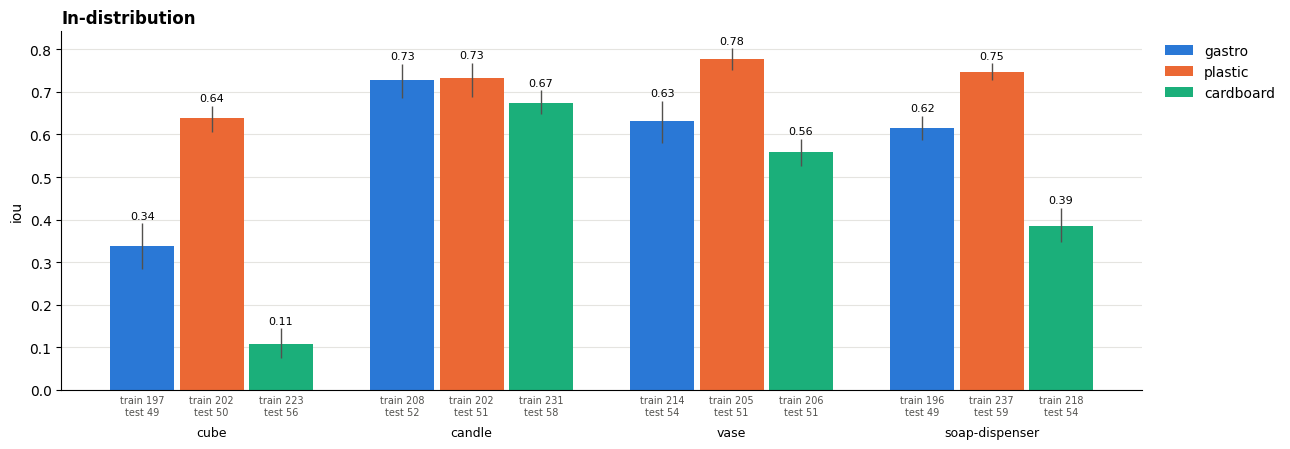

mean                   n_train                   n_test  \
run            gastro plastic cardboard  gastro plastic cardboard gastro   
item                                                                       
cube            0.338   0.637     0.109   197.0   202.0     223.0   49.0   
candle          0.729   0.732     0.674   208.0   202.0     231.0   52.0   
vase            0.633   0.777     0.558   214.0   205.0     206.0   54.0   
soap-dispenser  0.616   0.748     0.385   196.0   237.0     218.0   49.0   

                                  
run            plastic cardboard  
item                              
cube              50.0      56.0  
candle            51.0      58.0  
vase              51.0      51.0  
soap-dispenser    59.0      54.0

In [2]:
OBJECTS = ("cube", "candle", "vase", "soap-dispenser")
rows = []
for box, run in RUNS.items():
    H = REPO / "runs" / run / "outputs_history" / "eval" / box
    ep = max(int(f.name[2:6]) for f in H.rglob("ep*.pt"))
    for obj in OBJECTS:
        for f in sorted((H / obj).glob(f"ep{ep:04d}-*.pt")):
            d = torch.load(f, weights_only=False)
            rows += [dict(box=box, obj=obj, pos=p, iou=float(v)) for p, v in zip(d["info"]["position_id"].tolist(), d["metrics"]["iou"])]
iou = pd.DataFrame(rows)

def ci(g):   # 95% bootstrap CI of the mean, resampling positions
    s = g.groupby("pos").iou.agg(["sum", "count"]).to_numpy()
    idx = rng.integers(0, len(s), (1000, len(s)))
    return np.percentile(s[idx, 0].sum(1) / s[idx, 1].sum(1), [2.5, 97.5])

M, S = {}, {}
for box in BOXES:
    g = [iou[(iou.box == box) & (iou.obj == o)] for o in OBJECTS]
    M[box] = np.array([x.iou.mean() for x in g])
    S[box] = np.abs(np.array([ci(x) for x in g]).T - M[box])          # [mean − lo, hi − mean]
fig, ax = plt.subplots(figsize=(16, 5))
bars(ax, OBJECTS, M, S)
ax.set(ylabel="IoU", title="eval IoU, in-distribution objects (last epoch; whiskers = 95% CI over positions)")
plt.tight_layout()
iou.groupby(["obj", "box"]).agg(iou=("iou", "mean"), test_positions=("pos", "nunique")).unstack().loc[list(OBJECTS)].round(3)

**Reading:** The candle is about as good in cardboard as anywhere (0.73 / 0.73 / 0.67), and the vase is only a little lower (0.63 / 0.78 / 0.56). The cube falls from 0.64 (plastic) and 0.34 (gastro) to **0.11** in cardboard, the largest gap of any object. So cardboard is not useless as a sensor; it fails on the cube. From here on, only the cube (and the empty box) is used.

## 1.2 Load the Cube and Empty-Box Captures

Every per-capture quantity below is built from the PCLK output of one capture:

```
# per capture: speckle video → PCLK shift in px, per laser l (10×10 grid), frame t (2500 fps, 1.3 s), axis c ∈ {x, y}
s(l,t,c) = bandpass_100–1000Hz(shift(l,t,c)) · hann(t)            # post_process.clean
X(l,f,c) = rfft_t s(l,t,c),  keep 100 ≤ f ≤ 1000 Hz (1170 bins)    # post_process.fft, no scaling
x(l,j,c) = mean_{f ∈ band j} 20 log10 |X(l,f,c)|                  # 117 bands j of 10 bins (7.7 Hz), averaged in dB

D_spec(a, b) = sqrt( mean_{l,j,c} (x_a[l,j,c] − x_b[l,j,c])² )    # spectral distance between captures a, b, in dB; 100 × 117 × 2 = 23 400 terms
```

**Why 117 bands.** A capture is 3250 frames at 2500 fps, so the FFT has one bin every 2500 / 3250 ≈ 0.77 Hz, and 100-1000 Hz is 1170 bins. Averaging 10 neighbouring bins (in dB) gives 117 bands of 7.7 Hz: each value is less noisy and the vector is 10× shorter. The 10 is a choice, not physics. Gastro's resonances are only 1-3 Hz wide, so 7.7 Hz bands smear its sharpest peaks; section 4 checks whether that matters.

Captures are only ever compared within the **same speaker**.

**Standards** used in every section:
- Plots: line = **mean**, band or whisker = **±1 std** over the unit stated in the title (captures, pairs, speakers).
- Tables: `mean ± std` over the same unit.
- Averages are **means**, also over pairs and peaks. The median was checked for section 4 and gives the same numbers (within 0.03). One speaker has outlier pairs (cardboard speaker 3, ~4%), and they barely move its mean.
- Exceptions, each said where it happens: the IoU bars above (95% CI of a mean), and η in section 5 (mean of log10 η, because η spans two decades).
- Each box has one color. Noise is dashed in its box's color.

In [3]:
def meta(p): return {k: v for l in p.read_text().splitlines() if l.strip() for k, v in json.loads(l).items()}

rows = []
for box, d in BOXES.items():
    for p in sorted((REPO / "experiments" / d / "samples").glob("*/metadata.jsonl")):
        m = meta(p)
        is_cube = m.get("n_objects") == 1 and "red-cube" in m["objects"]
        if m["speaker"] not in SPEAKERS or not (is_cube or m.get("is_empty_box")) or any(s in m["layout"] for s in SKIP): continue
        com = m["avg_com"] if is_cube else [np.nan, np.nan]
        rows.append(dict(box=box, obj="cube" if is_cube else "empty", layout=m["layout"], pos=m["position_id"], spk=m["speaker"], t=pd.Timestamp(m["timestamp"]),
                         row=com[0], col=com[1], size=np.sqrt(m["crop_overhead_shape"][0] * m["crop_overhead_shape"][1]), dir=p.parent))
df = pd.DataFrame(rows)
empty, cube = df[df.obj == "empty"], df[df.obj == "cube"]

def fft(d): return np.load(d / "vibration/04_ffts.npz")["fft"][0]          # X: (100 lasers, 1170 freqs, 2 axes), complex
def load(d):
    A = np.abs(fft(d))
    return (20 * np.log10(A + 1e-12)).reshape(100, 117, 10, 2).mean(2).ravel(), (A ** 2).mean((0, 2)).reshape(117, 10).mean(1)
with ThreadPoolExecutor(32) as ex: feat, pw = map(np.stack, zip(*ex.map(load, df.dir)))   # x: (captures, 23 400) dB; mean |X|² per band: (captures, 117)
freqs = np.load(df.dir[0] / "vibration/04_ffts.npz")["freqs"]
fb = freqs.reshape(117, 10).mean(1)
pairs = {box: [(i, j) for _, g in empty[empty.box == box].groupby(["spk", "layout"]) for n, i in enumerate(g.index) for j in g.index[n + 1:]] for box in BOXES}   # back-to-back empty captures

def dist(a, b): return rms_dist(feat[a], feat[b])                                                # D_spec
def pos_dist(c): return cdist(*[c[["row", "col"]].to_numpy(float)] * 2) / c["size"].iloc[0]      # D_pos (section 4)
df.groupby(["obj", "box"]).agg(captures=("pos", "size"), positions=("pos", "nunique"), speakers=("spk", "nunique"))

captures  positions  speakers
obj   box                                     
cube  cardboard       837        279         3
      gastro          843        281         3
      plastic         756        252         3
empty cardboard        57         19         3
      gastro           36         12         3
      plastic          45         15         3

# 2 H1: The Cardboard Capture Is Noisier

**Hypothesis.** The cardboard capture is noisier (darker surface, longer exposure, a floppy box that never settles the same way twice). If true, two back-to-back captures of the empty cardboard box differ more than in the other boxes.

**Definitions.** `a`, `b` are two empty-box captures with the same speaker and layout, taken back to back. Nothing moved, so any difference between them is noise.

```
N(f)  = 10 log10( ½ mean_{l,c} (|X_a(l,f,c)| − |X_b(l,f,c)|)² )   # noise power per band, dB of |FFT|
noise = D_spec(a, b)                                             # one number per pair, in dB
```

`N(f)` is in absolute units, so a louder box also has more absolute noise. Whether the noise is large *relative to the signal* is the SNR, `L(f) − N(f)`, in section 3. (Scaling every capture to std 1 before computing `N` would ask the same question, but less cleanly: the std is dominated by the strongest resonances, so it rescales each box by a different part of its spectrum.)

The plot shows `N(f)` for every box, mean ± std over back-to-back pairs.

,gastro,plastic,cardboard
noise = D_spec of pairs (dB),1.45 ± 0.37,1.29 ± 0.34,1.64 ± 0.68
"N, mean over f (dB)",-28.6 ± 1.9,-29.9 ± 2.3,-25.5 ± 2.3
back-to-back pairs,36,45,63


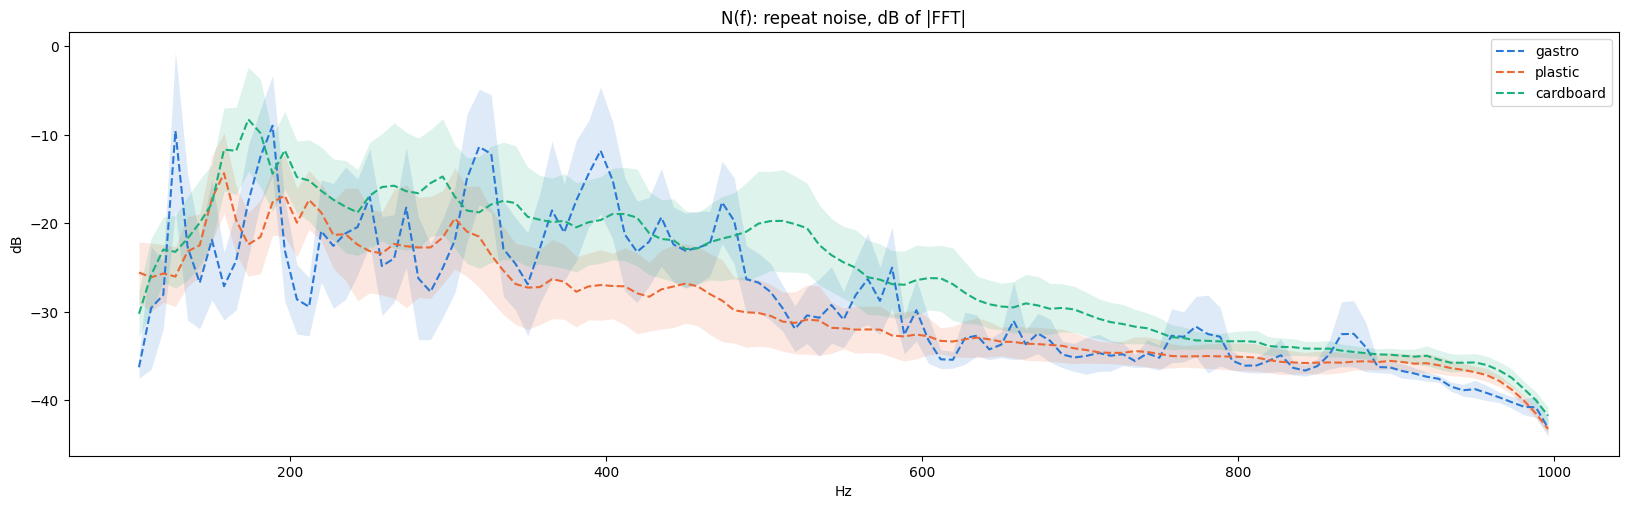

In [4]:
A = {i: np.abs(fft(df.dir[i])) for i in empty.index}
def noise_spec(i, j): return 10 * np.log10(((A[i] - A[j]) ** 2).mean((0, 2)).reshape(117, 10).mean(1) / 2)
noise = {box: np.stack([noise_spec(i, j) for i, j in pairs[box]]) for box in BOXES}

fig, ax = plt.subplots(figsize=(20, 5.5))
for box in BOXES: band(ax, fb, noise[box], COLORS[box], box, ls="--")
ax.set(xlabel="Hz", ylabel="dB", title="N(f): repeat noise, dB of |FFT|")
ax.legend()
summary["noise = D_spec of pairs (dB)"] = {box: pm([dist([i], [j])[0, 0] for i, j in pairs[box]]) for box in BOXES}
summary["N, mean over f (dB)"] = {box: pm(noise[box].mean(1), ".1f") for box in BOXES}
summary["back-to-back pairs"] = {box: str(len(pairs[box])) for box in BOXES}
show("noise = D_spec of pairs (dB)", "N, mean over f (dB)", "back-to-back pairs")

**Reading:**
- Cardboard's repeat noise is the highest, but only slightly: `D_spec` 1.64 dB vs 1.45 (gastro) and 1.29 (plastic), within one std of gastro.
- Per band, cardboard's noise is 2-4 dB above gastro and 4-6 dB above plastic between 200 and 700 Hz.
- That is absolute noise. Section 3 shows cardboard is also the loudest box, so per unit of signal (SNR) it is no noisier than gastro.
- Gastro's noise is spiky: it is largest exactly at its sharp resonances, where a tiny shift in a peak changes `|X|` a lot.

**H1 verdict: false as the explanation.** Cardboard is a little noisier than plastic but no noisier than gastro, which predicts the cube 3× better.

# 3 H2: The Cardboard Box Absorbs the Vibration

**Hypothesis.** Cardboard soaks up the speaker's energy, so the wall the lasers see barely moves. If true, the cardboard level is lower and closer to its noise.

**Definitions.** For one cube capture:

```
L(f)   = 10 log10( mean_{l,c} |X(l,f,c)|² )   # level per band, dB of |FFT| (same units as N)
SNR(f) = L(f) − N(f)                          # level above repeat noise, dB
```

PCLK measures motion in pixels. Phase correlation divides out brightness and Lucas-Kanade is a ratio of image gradients, so camera exposure (90 / 130 / 220 µs) does not scale `X`.

Top: `L(f)` mean ± std over cube captures, with the box's mean `N(f)` from section 2 dashed. Bottom: `SNR(f)`, the gap between the two, mean ± std over cube captures.

,gastro,plastic,cardboard
"level L, mean over f (dB)",-8.3 ± 1.7,-7.7 ± 2.2,-4.5 ± 2.8
"N, mean over f (dB)",-28.6 ± 1.9,-29.9 ± 2.3,-25.5 ± 2.3
"SNR = L − N, mean over f (dB)",20.3 ± 1.7,22.2 ± 2.2,21.0 ± 2.8


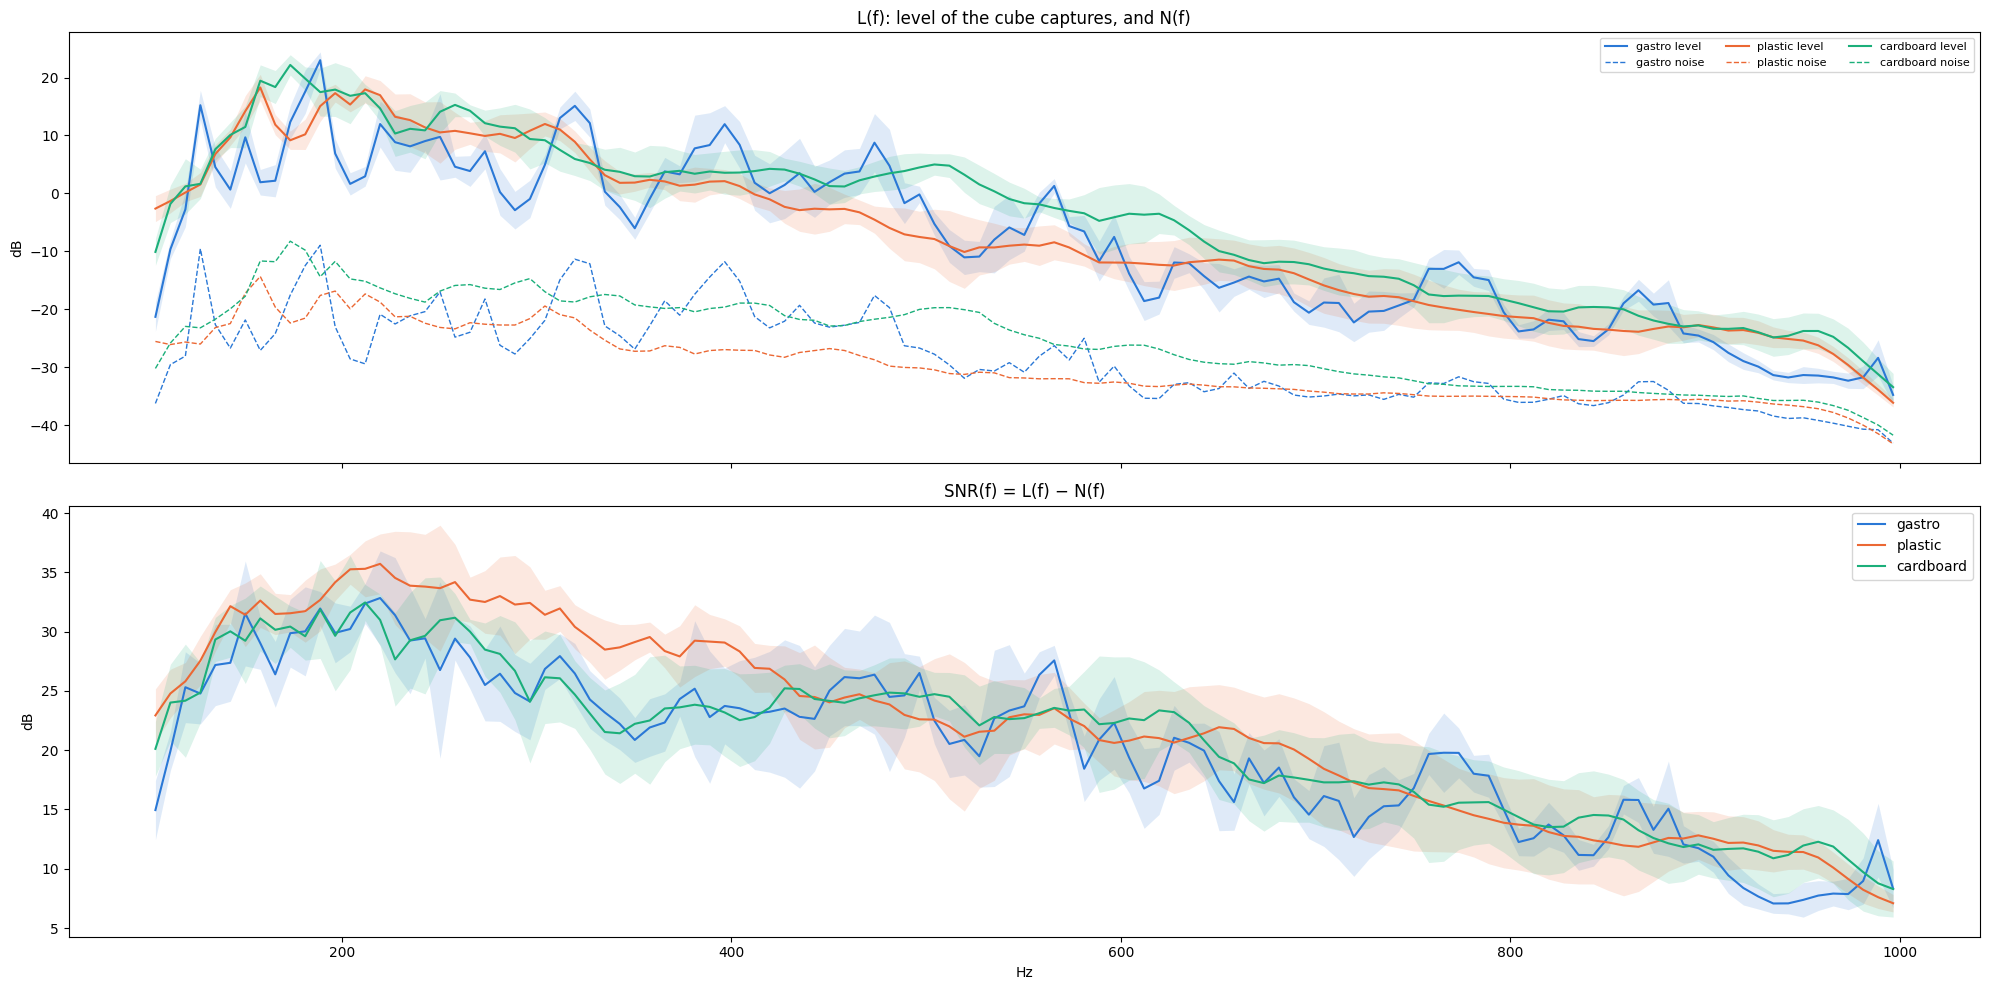

In [5]:
idx = {box: cube.index[cube.box == box] for box in BOXES}
L = {box: 10 * np.log10(pw[idx[box]]) for box in BOXES}                                       # (captures, 117)
SNR = {box: L[box] - noise[box].mean(0) for box in BOXES}                                       # (captures, 117)

fig, axs = plt.subplots(2, 1, figsize=(20, 10), sharex=True)
for box in BOXES:
    band(axs[0], fb, L[box], COLORS[box], f"{box} level")
    axs[0].plot(fb, noise[box].mean(0), c=COLORS[box], ls="--", lw=1, label=f"{box} noise")
    band(axs[1], fb, SNR[box], COLORS[box], box)
axs[0].set(ylabel="dB", title="L(f): level of the cube captures, and N(f)")
axs[1].set(xlabel="Hz", ylabel="dB", title="SNR(f) = L(f) − N(f)")
axs[0].legend(ncol=3, fontsize=8); axs[1].legend()
plt.tight_layout()
summary["level L, mean over f (dB)"] = {box: pm(L[box].mean(1), ".1f") for box in BOXES}
summary["SNR = L − N, mean over f (dB)"] = {box: pm(SNR[box].mean(1), ".1f") for box in BOXES}
show("level L, mean over f (dB)", "N, mean over f (dB)", "SNR = L − N, mean over f (dB)")

**Reading:**
- Cardboard is the **loudest** box, not the quietest: level −4.5 dB vs −8.3 (gastro) and −7.7 (plastic), highest between 400 and 700 Hz.
- Its noise is higher too, so its SNR (21.0 dB) sits between gastro (20.3) and plastic (22.2).
- SNR (bottom) is 25-35 dB below 400 Hz and falls to ~10 dB at 1000 Hz in every box. Plastic leads by ~5 dB between 250 and 400 Hz; above 450 Hz the three overlap. Cardboard tracks gastro almost everywhere.
- Texture differs: gastro's level and noise are jagged with sharp peaks, plastic's and cardboard's are smooth.

**H2 verdict: false.** Cardboard does not absorb the vibration: its wall moves the most, with an SNR between the other two.

# 4 H3: Moving the Cube Barely Changes the Spectrum

**Hypothesis.** To localize the cube, the spectrum has to change when the cube moves. If moving the cube in cardboard changes the spectrum less than recording twice does, there is nothing to learn.

**Definitions.** `a`, `b` are two cube captures with the same speaker; `com` is the cube's centre of mass in the overhead crop (`H × W` px).

```
D_pos(a, b) = ‖com_a − com_b‖ / sqrt(H · W)                                     # how far the cube moved, as a fraction of the box size
S(Δ)        = mean { D_spec(a, b) : spk_a = spk_b,  D_pos(a, b) ∈ [Δ, Δ + 0.04) }  # pooled over speakers
cue         = mean D_spec(cube capture, empty capture)                         # does the cube change the box at all?
move        = mean D_spec(D_pos > 0.25) − mean D_spec(0 < D_pos < 0.05)        # far pairs minus close pairs: the position signal
move/noise  = move / noise                                                       # position signal in units of repeat noise (section 2)
```

What each one asks:
- `S(Δ)`: if the cube moves `Δ × (box size)`, how much does the spectrum change? `Δ = 0.1` is 10% of the box (box size `sqrt(H·W)` = 1232 / 1151 / 1080 px). The bins are fixed and don't overlap.
- `cue`: **does the box notice the cube at all?** How different a cube capture looks from an empty capture.
- `move`: **does it notice where the cube is?** Two cube captures far apart (> a quarter of the box) against two close together (< 5% of the box). If position is encoded, far pairs differ much more than close pairs. It is the rise of the `S(Δ)` curve from left to right.
- `move/noise`: **is that position signal bigger than recording twice?** Below 1: moving the cube across the box changes the spectrum less than two back-to-back recordings of the same thing do. Above 1: position stands out from the noise.

`cue`, `move` and `move/noise` are computed per speaker; the table is mean ± std over speakers.

,gastro,plastic,cardboard
cue (dB),2.76 ± 0.06,4.37 ± 0.15,3.18 ± 0.48
move (dB),0.50 ± 0.02,1.31 ± 0.14,0.51 ± 0.11
move / noise,0.35 ± 0.07,1.03 ± 0.15,0.34 ± 0.12


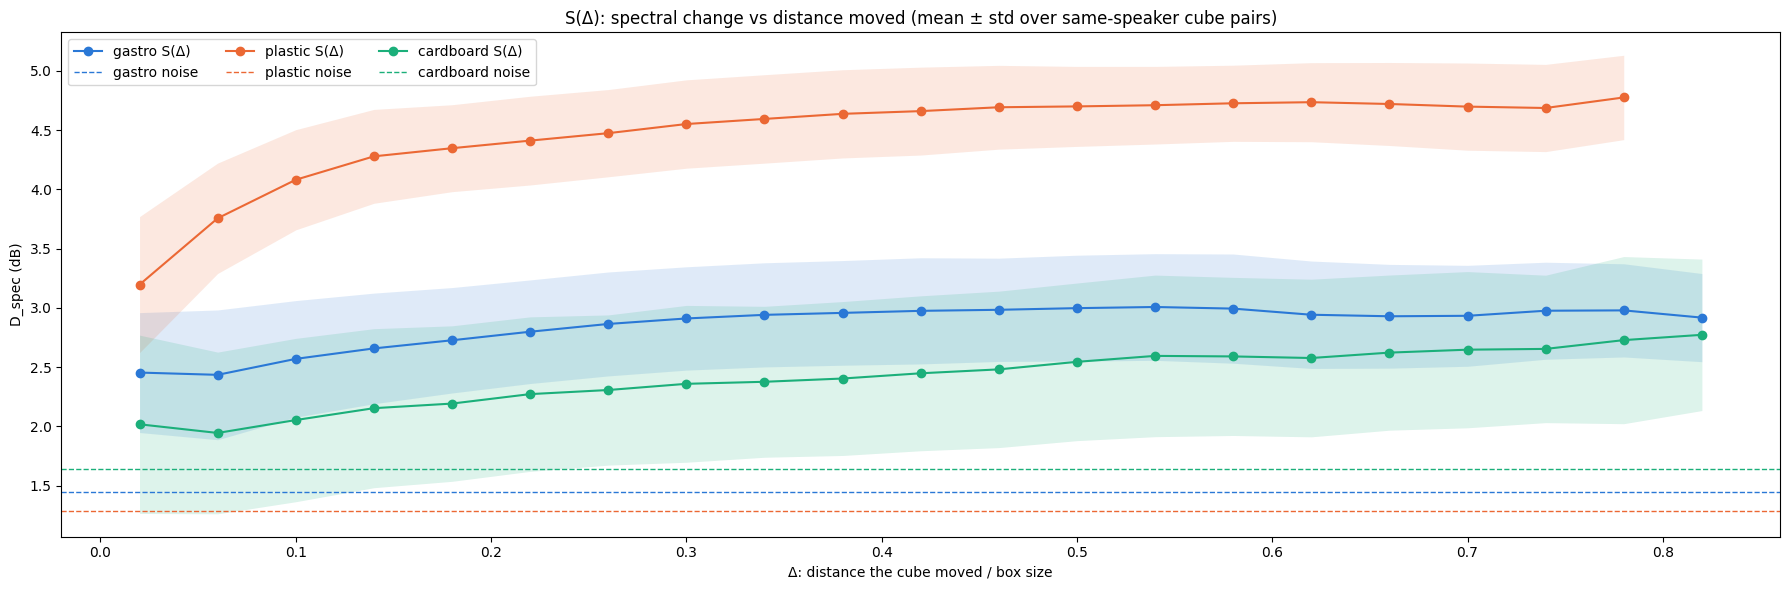

In [6]:
rows = []
for (box, spk), c in cube.groupby(["box", "spk"]):
    D, P = dist(c.index, c.index), pos_dist(c)
    nz = np.mean([dist([i], [j])[0, 0] for i, j in pairs[box] if df.spk[i] == spk])
    move = D[P > .25].mean() - D[(P > 0) & (P < .05)].mean()
    rows.append(dict(box=box, spk=spk, cue=np.mean(dist(c.index, empty.index[(empty.box == box) & (empty.spk == spk)])), move=move, noise=nz, move_noise=move / nz))
h3 = pd.DataFrame(rows)
for k, name in (("cue", "cue (dB)"), ("move", "move (dB)"), ("move_noise", "move / noise")): summary[name] = h3.groupby("box")[k].apply(pm).to_dict()

bins = np.arange(0, .85, .04)
fig, ax = plt.subplots(figsize=(18, 6))
for box in BOXES:
    d, p = [], []
    for _, c in cube[cube.box == box].groupby("spk"):
        iu = np.triu_indices(len(c), 1)
        d.append(dist(c.index, c.index)[iu]); p.append(pos_dist(c)[iu])
    s = pd.Series(np.concatenate(d)).groupby(pd.cut(np.concatenate(p), bins), observed=True).agg(["mean", "std"])
    x = [i.mid for i in s.index]
    ax.fill_between(x, s["mean"] - s["std"], s["mean"] + s["std"], color=COLORS[box], alpha=.15, lw=0)
    ax.plot(x, s["mean"], "o-", c=COLORS[box], label=f"{box} S(Δ)")
    ax.axhline(h3[h3.box == box].noise.mean(), c=COLORS[box], ls="--", lw=1, label=f"{box} noise")
ax.set(xlabel="Δ: distance the cube moved / box size", ylabel="D_spec (dB)", title="S(Δ): spectral change vs distance moved (mean ± std over same-speaker cube pairs)")
ax.legend(ncol=3)
plt.tight_layout()
show("cue (dB)", "move (dB)", "move / noise")

**Reading:**
- **cue:** every box notices the cube. Cardboard (3.2 dB) sits between gastro (2.8) and plastic (4.4).
- **move:** plastic's `S(Δ)` climbs 1.5 dB in the first 15% of the box, then flattens. Gastro and cardboard rise only about 0.5 dB over the whole box.
- **move/noise:** plastic is at 1.03: moving the cube changes the spectrum as much as recording twice. Gastro (0.35) and cardboard (0.34) are equal within one std: moving the cube across the whole box changes the spectrum only a third as much as recording twice.
- So the cardboard box notices *whether* there is a cube, but barely *where* it is. **Gastro is exactly as weak here**, yet it predicts the cube 3× better.
- Even the closest pairs (Δ < 0.04) sit well above the noise line in every box: two captures minutes apart differ more than two back-to-back ones, i.e. the setup drifts.

## 4.1 Does the 7.7 Hz Band Width Hide Gastro's Sharp Peaks?

`move/noise` recomputed with `x` averaged over 1, 2, 5 or 10 FFT bins per band (0.77 to 7.7 Hz), mean ± std over speakers. If gastro's position signal lives in its 1-3 Hz wide peaks, its `move/noise` should rise as the bands get narrower.

box,gastro,plastic,cardboard
hz,,,
0.77,0.12 ± 0.02,0.32 ± 0.08,0.11 ± 0.04
1.54,0.20 ± 0.03,0.52 ± 0.11,0.18 ± 0.07
3.85,0.29 ± 0.05,0.82 ± 0.15,0.28 ± 0.10
7.70,0.35 ± 0.07,1.03 ± 0.15,0.34 ± 0.12


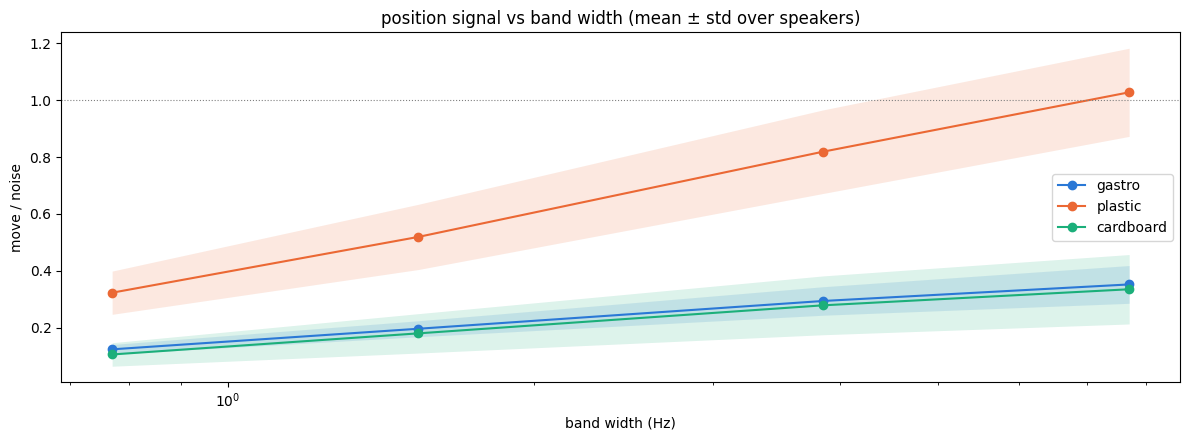

In [7]:
rows = []
for (box, spk), c in cube.groupby(["box", "spk"]):
    ids = list(c.index) + [i for p in pairs[box] for i in p if df.spk[i] == spk]
    with ThreadPoolExecutor(32) as ex: A = dict(zip(ids, ex.map(lambda i: 20 * np.log10(np.abs(fft(df.dir[i])) + 1e-12), ids)))   # (100, 1170, 2) dB
    P = pos_dist(c)
    for k in (1, 2, 5, 10):
        f = {i: A[i].reshape(100, 1170 // k, k, 2).mean(2).ravel() for i in A}
        d = lambda a, b: rms_dist(np.stack([f[i] for i in a]), np.stack([f[i] for i in b]))
        D = d(c.index, c.index)
        nz = np.mean([d([i], [j])[0, 0] for i, j in pairs[box] if df.spk[i] == spk])
        rows.append(dict(box=box, spk=spk, hz=.77 * k, move_noise=(D[P > .25].mean() - D[(P > 0) & (P < .05)].mean()) / nz))
bw = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(12, 4.5))
for box in BOXES: band(ax, sorted(bw.hz.unique()), bw[bw.box == box].pivot(index="spk", columns="hz", values="move_noise").to_numpy(), COLORS[box], box, marker="o")
ax.axhline(1, c="gray", lw=.8, ls=":")
ax.set(xscale="log", xlabel="band width (Hz)", ylabel="move / noise", title="position signal vs band width (mean ± std over speakers)")
ax.legend()
plt.tight_layout()
bw.groupby(["hz", "box"]).move_noise.apply(pm).unstack()[list(BOXES)]

**Reading:** Narrower bands make `move/noise` *smaller* in every box: each value gets noisier faster than the position signal grows. Gastro stays level with cardboard at every width (0.12 vs 0.11 at 0.77 Hz, 0.35 vs 0.34 at 7.7 Hz). So the 7.7 Hz bands do not hide a gastro advantage, and 117 bands is the best of the four widths for every box.

**H3 verdict: true for cardboard, but it does not explain the gap.** Moving the cube barely changes the cardboard spectrum (0.34), but the same is true of gastro (0.35), which works. Whatever makes cardboard worse than gastro has to be something `move/noise` does not see.

# 5 H4: The Cardboard Box Is Damped

**Hypothesis.** Cardboard is "dead": it loses its vibration energy quickly. Two material properties matter, and they do different things:
- **Stiffness** (elasticity) sets *where* the resonances are. A softer box has lower resonance frequencies.
- **Damping** (internal friction) sets *how wide* each resonance is and *how fast* vibration dies out. Cardboard is fibrous and layered, with folded, glued seams, so it should lose far more energy per cycle than metal or plastic.

Why damping could hurt localization: a cube shifts and reshapes the box's resonances. Sharp, long-ringing resonances make small shifts easy to see. Wide, quickly dying ones overlap, and a shift of one is blurred by its neighbours.

If true, cardboard rings for less time (5.1, 5.2) and has wider resonance peaks (5.3) than the other boxes.

Two measurements of the same property: the **envelope** is damping seen in time (how fast the response fades, summarized by T60), η is damping seen in frequency (how wide each peak is). They should agree (`T60 ≈ 2.2 / (η f0)`). **Time to noise** also depends on how far the response starts above the noise floor, so it mixes damping with dynamic range.

**Definitions: damping** (empty captures; computed from the raw PCLK shifts `02_raw_shifts.npy`, band-passed 100-1000 Hz but **without** the Hann window):

```
FRF            H(l,f,c) = X(l,f,c) / C(f)                         # C = spectrum of the chirp that was played (log sweep 100→1000 Hz, 1 s, from 0.1 s)
impulse resp.  h(l,t,c) = irfft_f H(l,f,c)                        # the wall's response to one short speaker pulse (swept-sine method)
envelope       E(t) = 10 log10( smooth_10ms mean_{l,c} h(l,t,c)² )  # dB re its peak, per frequency band
noise floor    E_n  = the same for h of the silent first 0.14 s (before the chirp), as energy per sample; flat in time
time to noise  t_n  = first t with E(t) ≤ E_n + 1 dB              # after this the response can't be told apart from noise
T60            = −60 / slope of a line fit to E(t) from −5 to −25 dB   # time to fade 60 dB
loss factor    η  = Δf / f0                                       # width at half power (−3 dB) of a resonance peak / its frequency
               2πη = fraction of the stored energy lost per cycle;   Q = 1/η;   T60 ≈ 2.2 / (η f0)
```

This is all passive: nothing touches the box. A chirp is a stretched-out impulse, so dividing it out gives the response to one speaker pulse. Checks: the bumps at 0.82 s and 1.0 s in the envelopes are where a log sweep puts the 3rd and 2nd harmonic-distortion responses. Caveat: the sweep ends ~0.1 s before the capture does, so tails longer than that above ~500 Hz are cut. That only affects gastro, which rings far longer than this anyway.

η uses peaks ≥ 6 dB above the local trend (rolling median over ~78 Hz; a median so the peaks themselves do not lift the trend), and only if both −3 dB points are reached before the next peak, so overlapping peaks are skipped. The 6 dB is a detection threshold (a choice); the −3 dB is the definition of η.

In [8]:
FPS, NT = 2500, 3250
C = np.fft.rfft(np.concatenate([np.zeros(250), chirp(np.arange(FPS) / FPS, f0=100, t1=1.0, f1=1000, method="logarithmic"), np.zeros(NT - 2750)]))   # the chirp at the camera rate
fr = np.fft.rfftfreq(NT, 1 / FPS)
inband = (fr >= 100) & (fr <= 1000)
sos = butter(5, [100, 1000], fs=FPS, btype="band", output="sos")
QUIET = slice(25, 375)   # samples before the chirp arrives (it starts ~0.17 s in)
NQ = QUIET.stop - QUIET.start
OCT = [(100, 200), (200, 400), (400, 800)]

def deconv(x): return np.where(inband[None, :, None], np.fft.rfft(x, axis=1) / C[None, :, None], 0)
def capture(i):   # FRF H, impulse response h (direct arrival at t = 0), and hn: the same for the silent start only
    x = sosfiltfilt(sos, np.load(df.dir[i] / "vibration/02_raw_shifts.npy"), axis=1)
    n = np.zeros_like(x); n[:, QUIET] = x[:, QUIET]
    H = deconv(x)
    h = np.fft.irfft(H, n=NT, axis=1)
    return H, np.roll(h, -(h ** 2).mean((0, 2)).argmax(), axis=1), np.fft.irfft(deconv(n), n=NT, axis=1)

def octave(h, lo, hi): return sosfiltfilt(butter(4, [lo, hi], fs=FPS, btype="band", output="sos"), h, axis=1)
def energy(h, lo, hi): return np.convolve((octave(h, lo, hi) ** 2).mean((0, 2)), np.ones(25) / 25, "same")
def env(h, lo, hi): e = energy(h, lo, hi); return 10 * np.log10(e / e.max())
def floor(h, hn, lo, hi): return 10 * np.log10((octave(hn, lo, hi) ** 2).mean((0, 2)).sum() / NQ / energy(h, lo, hi).max())   # NQ samples of noise -> energy per sample
def t_noise(e, fl): hit = np.flatnonzero(e[:int(.75 * FPS)] <= fl + 1); return hit[0] / FPS if len(hit) else np.nan   # stop at 0.75 s, before the distortion echoes
def t60(e):
    a, b = np.argmax(e < -5), min(np.argmax(e < -25) or 1875, 1875)
    return -60 / np.polyfit(np.arange(a, b) / FPS, e[a:b], 1)[0]

def modes(H):
    P = (np.abs(H[:, inband]) ** 2).mean((0, 2)); f = fr[inband]; db = 10 * np.log10(P)
    pk, _ = find_peaks(db - pd.Series(db).rolling(101, center=True, min_periods=1).median().to_numpy(), prominence=6, distance=3)
    _, lb, rb = peak_prominences(P, pk)
    ok = (P[lb] < P[pk] / 2) & (P[rb] < P[pk] / 2)
    pk, lb, rb = pk[ok], lb[ok], rb[ok]
    return f[pk], peak_widths(P, pk, rel_height=.5, prominence_data=(P[pk], lb, rb))[0] * (fr[1] - fr[0]) / f[pk]   # width at P/2

rows, example = [], {}
for i in empty.index:
    H, h, hn = capture(i)
    f0, eta = modes(H)
    r = dict(box=df.box[i], spk=df.spk[i], f0=f0, etas=eta, eta=10 ** np.log10(eta).mean(), env=env(h, 100, 1000), floor=floor(h, hn, 100, 1000))
    r["t_noise"] = t_noise(r["env"], r["floor"])
    for lo, hi in OCT:
        e = env(h, lo, hi)
        r[f"t_noise {lo}-{hi}"], r[f"T60 {lo}-{hi}"] = t_noise(e, floor(h, hn, lo, hi)), t60(e)
    rows.append(r)
    if df.spk[i] == 1 and df.box[i] not in example: example[df.box[i]] = h, hn, r
dmp = pd.DataFrame(rows)
dmp.groupby("box").size().rename("empty captures").to_frame().T[list(BOXES)]

box,gastro,plastic,cardboard
empty captures,36,45,57


## 5.1 One Capture per Box

Left: the impulse response of one laser (55, x axis), scaled to its peak; the gray band is ±1 rms of the noise (about 1% of the peak, too thin to see). Right: the envelope over 100-1000 Hz, mean over lasers, with the noise floor dashed. The black line is where the response dies into noise.

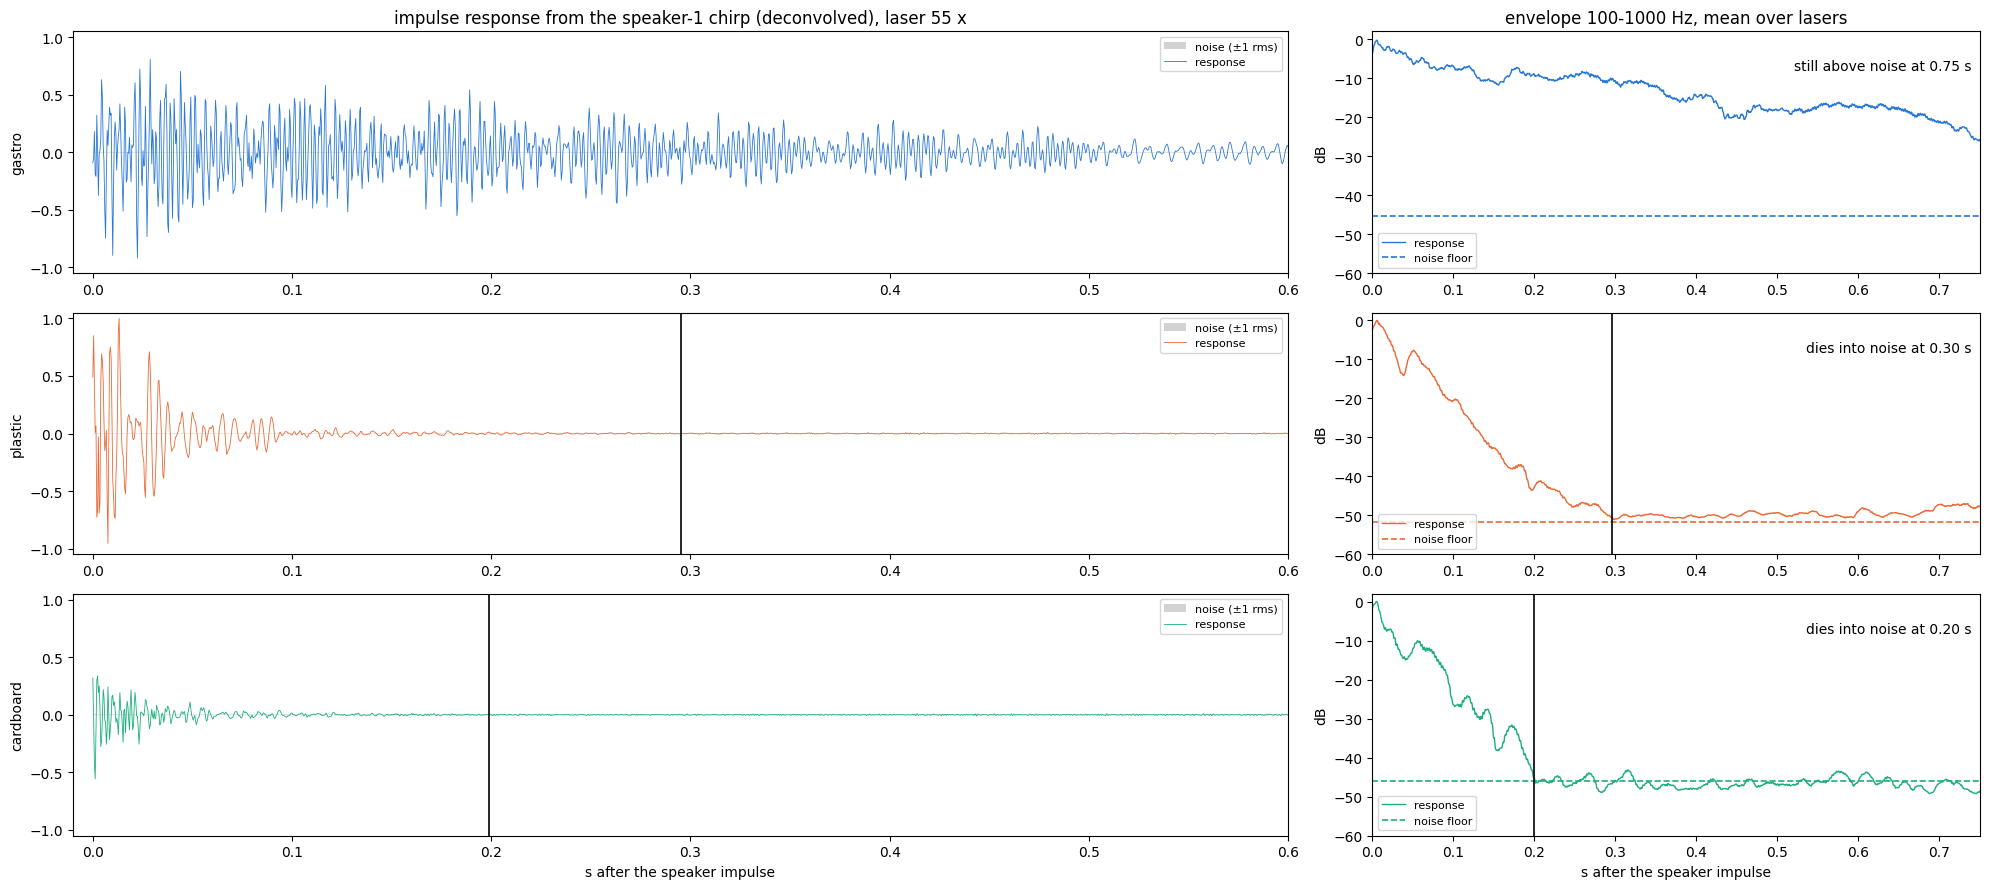

In [9]:
tt = np.arange(NT) / FPS
fig, axs = plt.subplots(3, 2, figsize=(20, 9), gridspec_kw=dict(width_ratios=[2, 1]))
for row, box in enumerate(BOXES):
    h, hn, r = example[box]
    a = np.abs(h[55, :, 0]).max()
    rms = np.sqrt((hn[55, :, 0] ** 2).sum() / NQ) / a
    axs[row, 0].fill_between(tt, -rms, rms, color="gray", alpha=.35, lw=0, label="noise (±1 rms)")
    axs[row, 0].plot(tt, h[55, :, 0] / a, c=COLORS[box], lw=.6, label="response")
    axs[row, 0].set(xlim=(-.01, .6), ylim=(-1.05, 1.05), ylabel=box, title="impulse response from the speaker-1 chirp (deconvolved), laser 55 x" if row == 0 else "")
    axs[row, 0].legend(loc="upper right", fontsize=8)
    axs[row, 1].plot(tt, r["env"], c=COLORS[box], lw=1, label="response")
    axs[row, 1].axhline(r["floor"], c=COLORS[box], ls="--", lw=1.2, label="noise floor")
    if np.isfinite(r["t_noise"]):
        for ax in axs[row]: ax.axvline(r["t_noise"], c="k", lw=1.2)
    axs[row, 1].text(.74, -8, f"dies into noise at {r['t_noise']:.2f} s" if np.isfinite(r["t_noise"]) else "still above noise at 0.75 s", ha="right", fontsize=10)
    axs[row, 1].set(xlim=(0, .75), ylim=(-60, 2), ylabel="dB", title="envelope 100-1000 Hz, mean over lasers" if row == 0 else "")
    axs[row, 1].legend(fontsize=8, loc="lower left")
axs[-1, 0].set_xlabel("s after the speaker impulse"); axs[-1, 1].set_xlabel("s after the speaker impulse")
plt.tight_layout()

**Reading:** Gastro keeps ringing past 0.5 s and is still ~20 dB above its floor at 0.75 s. Plastic dies into noise at 0.30 s, cardboard at 0.20 s. In the waveform, cardboard's response is essentially gone after ~0.1 s.

## 5.2 All Empty Captures

Envelope over 100-1000 Hz, mean ± std over all empty captures of each box (all speakers), with the mean noise floor dashed and the mean time to noise dotted. Averaging the impulse responses themselves would cancel them out (their phase differs between speakers and captures), so only the envelope is averaged.

,gastro,plastic,cardboard
time to noise 100-1000 Hz (s),0.56 ± 0.09 (33% reach it),0.37 ± 0.08,0.22 ± 0.03
time to noise 100-200 Hz (s),0.65 ± 0.07 (25% reach it),0.42 ± 0.10 (98% reach it),0.23 ± 0.03
time to noise 200-400 Hz (s),0.43 ± 0.05 (33% reach it),0.29 ± 0.04,0.22 ± 0.03
time to noise 400-800 Hz (s),0.45 ± 0.11 (69% reach it),0.18 ± 0.02,0.20 ± 0.03
T60 100-200 Hz (s),3.55 ± 0.36,0.34 ± 0.06,0.38 ± 0.13
T60 200-400 Hz (s),1.85 ± 0.14,0.23 ± 0.03,0.22 ± 0.07
T60 400-800 Hz (s),1.40 ± 0.29,0.17 ± 0.04,0.12 ± 0.02


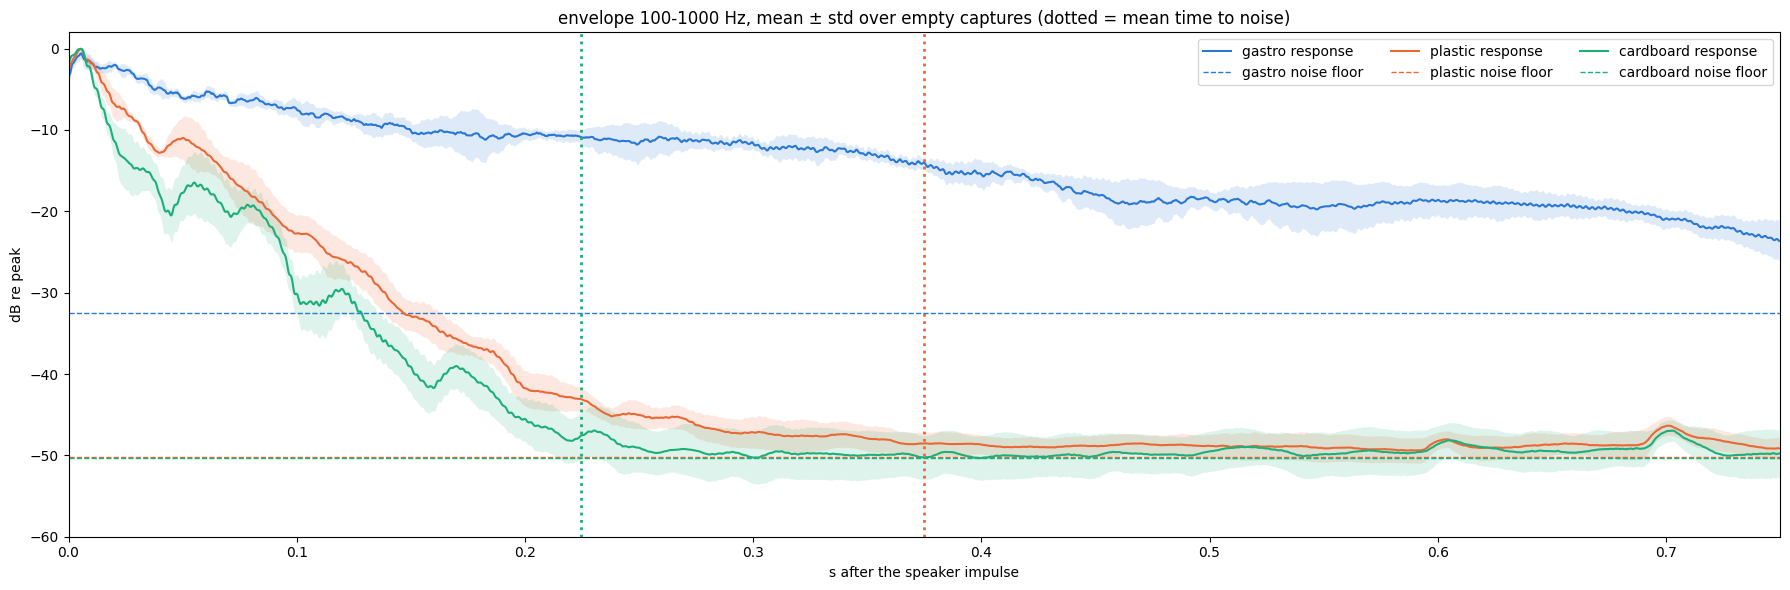

In [10]:
T = int(.75 * FPS)
fig, ax = plt.subplots(figsize=(18, 6))
for box in BOXES:
    g = dmp[dmp.box == box]
    band(ax, tt[:T], np.stack(g.env)[:, :T], COLORS[box], f"{box} response")
    ax.axhline(g.floor.mean(), c=COLORS[box], ls="--", lw=1, label=f"{box} noise floor")
    if g.t_noise.notna().mean() > .5: ax.axvline(g.t_noise.mean(), c=COLORS[box], ls=":", lw=2)
ax.set(xlim=(0, .75), ylim=(-60, 2), xlabel="s after the speaker impulse", ylabel="dB re peak", title="envelope 100-1000 Hz, mean ± std over empty captures (dotted = mean time to noise)")
ax.legend(ncol=3)
plt.tight_layout()

def tn(v):
    v = np.asarray(v, float)
    if not np.isfinite(v).any(): return "> 0.75 (never within 0.75 s)"
    return pm(v) + ("" if np.isfinite(v).all() else f" ({np.isfinite(v).mean():.0%} reach it)")
summary["time to noise 100-1000 Hz (s)"] = dmp.groupby("box").t_noise.apply(tn).to_dict()
for lo, hi in OCT: summary[f"time to noise {lo}-{hi} Hz (s)"] = dmp.groupby("box")[f"t_noise {lo}-{hi}"].apply(tn).to_dict()
for lo, hi in OCT: summary[f"T60 {lo}-{hi} Hz (s)"] = dmp.groupby("box")[f"T60 {lo}-{hi}"].apply(pm).to_dict()
show("time to noise 100-1000 Hz (s)", *[f"time to noise {lo}-{hi} Hz (s)" for lo, hi in OCT], *[f"T60 {lo}-{hi} Hz (s)" for lo, hi in OCT])

**Reading:**
- The picture holds across every capture, with tight bands: cardboard reaches its noise floor in 0.22 ± 0.03 s, plastic in 0.37 ± 0.08 s. Gastro mostly doesn't within 0.75 s.
- T60: gastro 1.4-3.6 s, plastic 0.17-0.34 s, cardboard 0.12-0.38 s. Cardboard decays fastest above 400 Hz (0.12 vs 0.17 s for plastic), but plastic is close.
- Gastro's mean noise floor (−32 dB) is far above its value in one capture (−45 dB, 5.1). Gastro rings for seconds, so the "silent" start of a capture still holds the previous chirp's ringing. Its floor and time to noise are therefore unreliable; the 33% that "reach it" hit that inflated floor.
- The bumps at 0.6 and 0.7 s are the 5th and 4th harmonic-distortion responses of the log sweep, not ringing.

## 5.3 Loss Factor of Every Mode

Dots: η of every resonance peak in every empty capture. Lines: per 100 Hz band, mean ± std of log10 η (η spans two decades, so the mean is taken on a log scale), bands with ≥ 5 peaks, joined into one line per box. The dotted line is a peak 1 FFT bin wide: narrower peaks can't be resolved, so gastro's smallest values are upper limits.

,gastro,plastic,cardboard
η (log-mean per capture),0.006 ± 0.001,0.039 ± 0.007,0.055 ± 0.015
energy lost per cycle 2πη (%),4 ± 0,24 ± 4,34 ± 9
Q = 1/η,167 ± 23,27 ± 5,19 ± 5
measurable modes per capture,42 ± 4,4 ± 1,4 ± 2


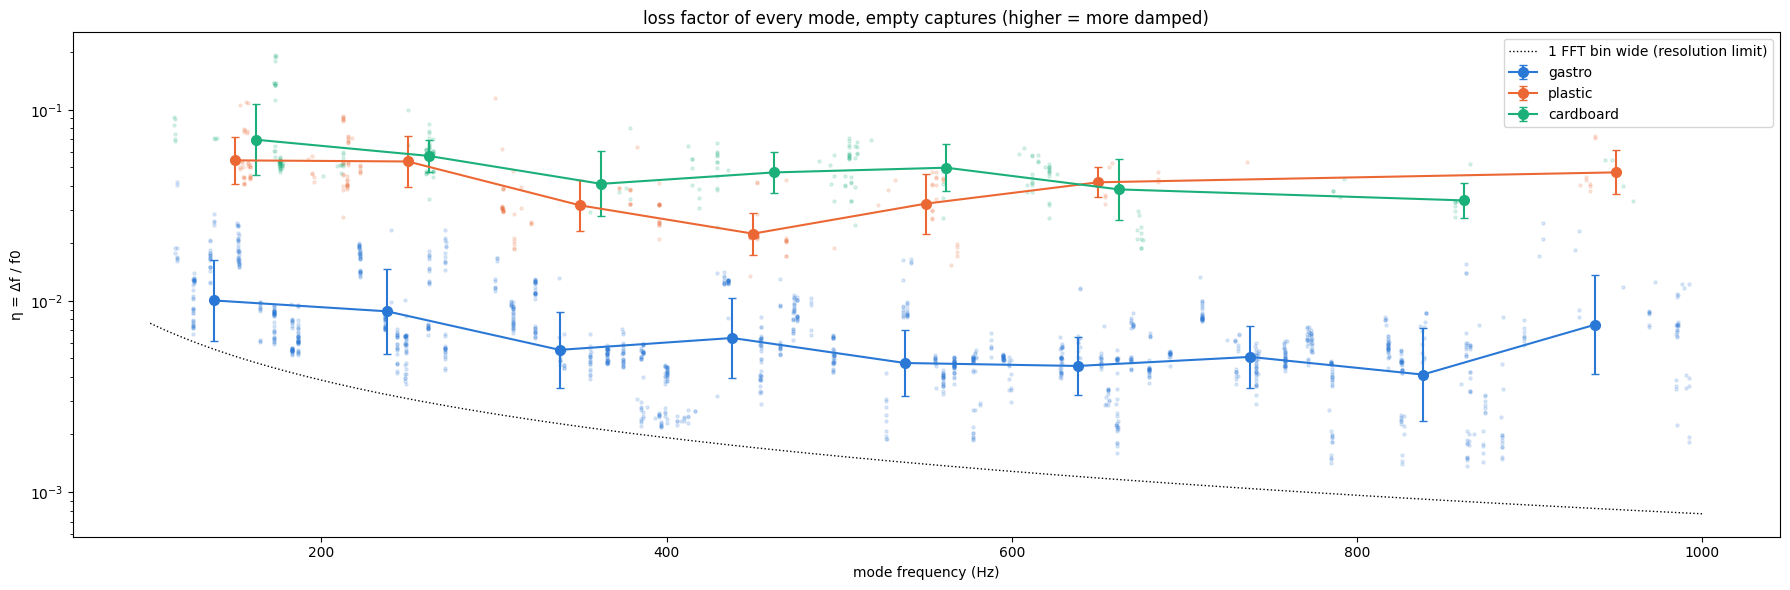

In [11]:
fig, ax = plt.subplots(figsize=(18, 6))
for k, box in enumerate(BOXES):
    g = dmp[dmp.box == box]
    f0, eta = np.concatenate(g.f0.to_list()), np.concatenate(g.etas.to_list())
    ax.scatter(f0, eta, s=5, alpha=.15, c=COLORS[box])
    st = pd.Series(np.log10(eta)).groupby((f0 // 100).astype(int)).agg(["mean", "std", "size"])
    st = st[st["size"] >= 5]
    m, lo, hi = 10 ** st["mean"], 10 ** (st["mean"] - st["std"]), 10 ** (st["mean"] + st["std"])
    ax.errorbar(st.index * 100 + 50 + (k - 1) * 12, m, yerr=[m - lo, hi - m], fmt="o-", c=COLORS[box], capsize=3, ms=7, label=box)
ax.plot(fr[inband], (fr[1] - fr[0]) / fr[inband], c="k", lw=1, ls=":", label="1 FFT bin wide (resolution limit)")
ax.set(yscale="log", xlabel="mode frequency (Hz)", ylabel="η = Δf / f0", title="loss factor of every mode, empty captures (higher = more damped)")
ax.legend()
plt.tight_layout()

summary["η (log-mean per capture)"] = dmp.groupby("box").eta.apply(lambda v: pm(v, ".3f")).to_dict()
summary["energy lost per cycle 2πη (%)"] = dmp.groupby("box").eta.apply(lambda v: pm(200 * np.pi * v, ".0f")).to_dict()
summary["Q = 1/η"] = dmp.groupby("box").eta.apply(lambda v: pm(1 / v, ".0f")).to_dict()
summary["measurable modes per capture"] = dmp.groupby("box").f0.apply(lambda v: pm([len(x) for x in v], ".0f")).to_dict()
show("η (log-mean per capture)", "energy lost per cycle 2πη (%)", "Q = 1/η", "measurable modes per capture")

**Reading:**
- Two clean groups. Gastro's modes have η 0.002-0.02 (log-mean 0.006: 4% of the energy lost per cycle, Q ≈ 170). Plastic and cardboard sit at 0.02-0.2 (0.039 and 0.055: 24-34% lost per cycle, Q ≈ 20-27).
- Cardboard is the most damped in most bands, but plastic overlaps it.
- Only ~4 peaks per capture are measurable in plastic and cardboard, vs ~42 in gastro: their resonances are too broad and run into each other.
- So **damping separates gastro from the other two, not cardboard from plastic**, and plastic predicts the cube best.
- Caveat: a wide surviving peak may be several merged modes (η too high), while T60 follows the slowest modes (too long). η predicts T60 ≈ 2.2 / (η f) ≈ 0.07-0.09 s at 600 Hz vs 0.12-0.20 s measured; the true damping of plastic and cardboard is in between. The ranking does not depend on this.

**H4 verdict: true, but shared with plastic.** Cardboard is the most damped box (η 0.055, fastest decay above 400 Hz, ~4 measurable modes), but plastic is nearly as damped (η 0.039, also ~4 modes) and predicts the cube best. Damping cannot be the explanation by itself.

# 6 H5: Cardboard Has Few Distinct Spatial Patterns

**Hypothesis.** What the model sees is a 10×10 grid of lasers. A cube at a new position can only change the input in as many independent ways as the wall has distinct spatial patterns (mode shapes). The usual story ties this to damping:

```
high damping → each resonance peak is wide → neighbouring resonances overlap
             → at any frequency the wall shows a blend of many modes
             → the spatial pattern on the wall changes slowly with frequency
             → few distinct spatial patterns → few ways for the cube's position to show up
```

H4 showed plastic is about as damped as cardboard, so this chain is not automatic, and plastic tests it. If H5 is true, cardboard has fewer distinct spatial patterns than **both** other boxes, plastic included.

**Definitions.** For one capture, `X` is a `1170 × 200` matrix: row `f` is the complex FFT over 100 lasers × 2 axes at frequency `f`, scaled to unit length (this removes how loud the speaker is at `f`, not where it sits, so everything is computed within one speaker).

```
X = U S Vᴴ                         # SVD; columns of V = spatial patterns on the 10×10 grid
s_k² = Σ_f |x_f · v_k|²            # energy of pattern k, summed over frequencies
eff_rank = (Σ s²)² / Σ s⁴          # = r if the energy is spread evenly over r patterns; 1 if one pattern holds everything
n90 = number of patterns holding 90% of the energy
MAC(f, f') = |x_f · x_f'|²         # 1 = same spatial shape at f and f', 0 = unrelated;  eff_rank = n_f² / Σ MAC
```

- `eff_rank cube`, `eff_rank empty`: eff_rank of each capture, mean over captures.
- `eff_rank all`: stack every cube and empty capture of one speaker into one tall matrix; this also counts patterns that only appear as the cube moves.
- Every metric is computed per speaker; bars are mean ± std over speakers.

`eff_rank` and `n90` summarize the same singular values but weigh them differently. `eff_rank` is set by the strongest patterns: how many carry most of the energy, roughly equally. `n90` is set by the tail: how many it takes to cover 90%, counting every weak one. Both are about **space**. The `measurable modes` count in H4 is about **frequency** (how many resonances are sharp enough to tell apart); the two need not agree.

## 6.1 Number of Distinct Patterns

,gastro,plastic,cardboard
eff_rank all,9.2 ± 0.2,8.4 ± 0.4,5.4 ± 0.8
eff_rank cube,9.1 ± 0.2,7.8 ± 0.4,5.4 ± 0.8
eff_rank empty,9.0 ± 0.2,7.8 ± 0.4,5.4 ± 0.8
n90,13.0 ± 0.8,13.7 ± 3.1,8.3 ± 2.1
measurable modes per capture,42 ± 4,4 ± 1,4 ± 2


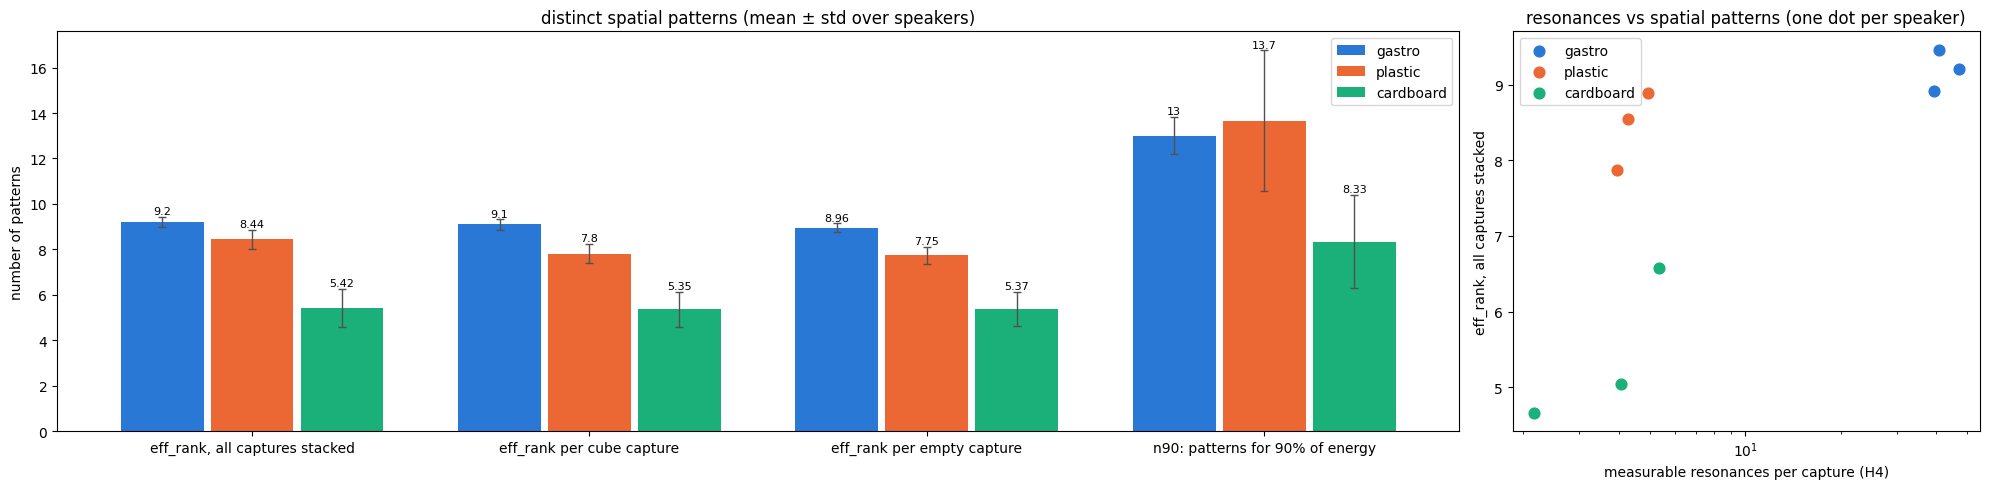

In [12]:
def unit(F):
    X = F.transpose(1, 0, 2).reshape(F.shape[1], -1)
    return X / np.linalg.norm(X, axis=1, keepdims=True)
def pr(s): return s.sum() ** 2 / (s ** 2).sum()            # eff_rank from energies s = singular values²

rank, mac = [], {box: 0 for box in BOXES}
for (box, spk), g in df.groupby(["box", "spk"]):
    with ThreadPoolExecutor(32) as ex: X = np.stack(list(ex.map(lambda d: unit(fft(d)), g.dir)))   # (captures, freqs, 200)
    G = X.conj().transpose(0, 2, 1) @ X                      # XᴴX per capture: (captures, 200, 200)
    s = np.linalg.eigvalsh(G.sum(0))[::-1]                   # stacked matrix: its XᴴX is the sum, eigenvalues = singular values²
    each = np.array([pr(e) for e in np.linalg.eigvalsh(G)])
    rank.append(dict(box=box, spk=spk, all=pr(s), cube=each[(g.obj == "cube").to_numpy()].mean(), empty=each[(g.obj == "empty").to_numpy()].mean(),
                     n90=np.searchsorted(np.cumsum(s) / s.sum(), .9) + 1, cum=np.cumsum(s) / s.sum()))
    mac[box] = mac[box] + sum(np.abs(x[::5] @ x[::5].conj().T) ** 2 for x in X) / (df.box == box).sum()   # every 5th freq
rank = pd.DataFrame(rank)
for k in ("all", "cube", "empty", "n90"): summary[f"eff_rank {k}" if k != "n90" else "n90"] = rank.groupby("box")[k].apply(lambda v: pm(v, ".1f")).to_dict()

cols = ["all", "cube", "empty", "n90"]
fig, axs = plt.subplots(1, 2, figsize=(20, 5), gridspec_kw=dict(width_ratios=[3, 1]))
bars(axs[0], ["eff_rank, all captures stacked", "eff_rank per cube capture", "eff_rank per empty capture", "n90: patterns for 90% of energy"],
     {b: rank[rank.box == b][cols].mean().to_numpy() for b in BOXES}, {b: rank[rank.box == b][cols].std(ddof=0).to_numpy() for b in BOXES})
axs[0].set(ylabel="number of patterns", title="distinct spatial patterns (mean ± std over speakers)")
res = dmp.assign(n=dmp.f0.map(len)).groupby(["box", "spk"]).n.mean()   # measurable resonances per empty capture (H4), mean per speaker
for box in BOXES:
    r = rank[rank.box == box].set_index("spk")
    axs[1].scatter(res[box].loc[r.index], r["all"], s=60, c=COLORS[box], label=box)
axs[1].set(xscale="log", xlabel="measurable resonances per capture (H4)", ylabel="eff_rank, all captures stacked", title="resonances vs spatial patterns (one dot per speaker)")
axs[1].legend()
plt.tight_layout()
show("eff_rank all", "eff_rank cube", "eff_rank empty", "n90", "measurable modes per capture")

**Reading:**
- **Cardboard is lowest on every measure, in every speaker:** eff_rank 5.4 vs 9.0-9.2 (gastro) and 7.8-8.4 (plastic), and n90 8.3 vs 13 and 13.7.
- **eff_rank and n90 split gastro and plastic.** Gastro has the higher eff_rank (9.2 vs 8.4) but the slightly lower n90 (13 vs 13.7): about 9 strong, roughly equal patterns and a short tail. Plastic has slightly fewer dominant patterns but a long tail of weak ones: its shape drifts smoothly with frequency (see the MAC below).
- **Broad peaks do not force few patterns** (right). Plastic and cardboard both have only ~4 measurable resonances per capture (H4), yet every plastic speaker has more patterns (eff_rank 7.9-8.9) than every cardboard speaker (4.7-6.6). Gastro has 42 resonances but only ~9 patterns: many resonances share a shape. (n90 separates plastic from cardboard less cleanly per speaker, 11-18 vs 6-11, so the panel uses eff_rank.) The number of resonances is a damping readout; the number of patterns is what H5 is about.
- Cube ≈ empty, and `all` ≈ per capture: moving the cube adds almost no new patterns in any box.

## 6.2 Cumulative Energy

`Σ_{j≤k} s_j² / Σ s²` of the stacked matrix, mean ± std over speakers. A curve that rises fast = few patterns. eff_rank summarizes how fast it rises; n90 is where it crosses the dotted line.

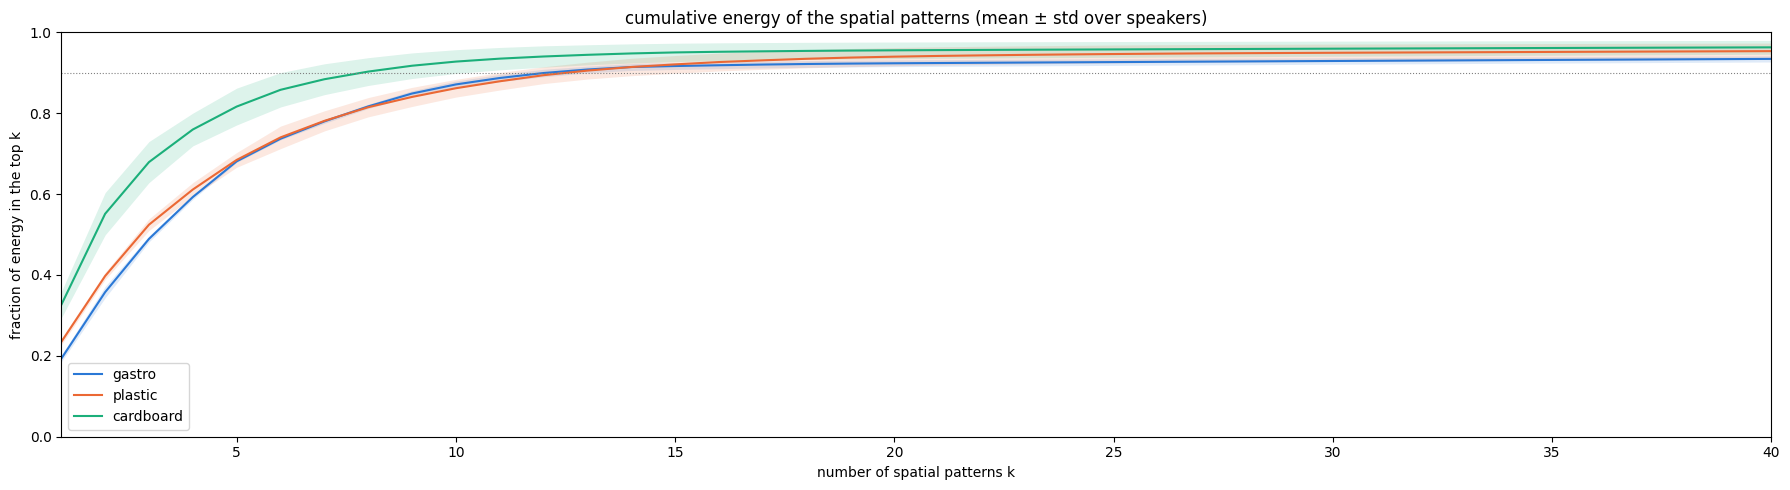

In [13]:
fig, ax = plt.subplots(figsize=(18, 5))
for box in BOXES: band(ax, np.arange(1, 41), np.stack(rank[rank.box == box].cum)[:, :40], COLORS[box], box)
ax.axhline(.9, c="gray", lw=.8, ls=":")
ax.set(xlabel="number of spatial patterns k", ylabel="fraction of energy in the top k", title="cumulative energy of the spatial patterns (mean ± std over speakers)", xlim=(1, 40), ylim=(0, 1))
ax.legend()
plt.tight_layout()

**Reading:** Cardboard's top 2 patterns hold 56% of the energy, vs ~37% for gastro and plastic, and it reaches 90% with 8 patterns vs ~12-13. Gastro and plastic rise together for the first ~10 patterns; plastic's long tail then takes it slightly longer to reach 90%.

## 6.3 MAC Matrix

Mean over every cube and empty capture of the box, every 5th frequency. Big bright blocks = one shape over a wide band = low eff_rank. A thin diagonal = the shape keeps changing with frequency = high eff_rank.

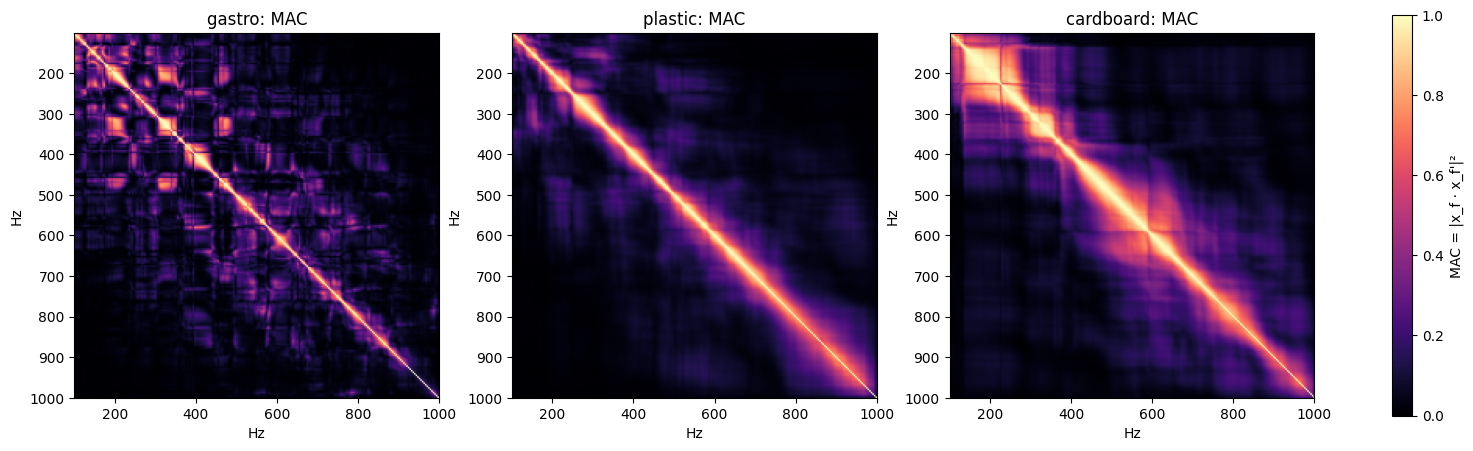

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, box in zip(axs, BOXES):
    im = ax.imshow(mac[box], extent=(freqs[0], freqs[-1], freqs[-1], freqs[0]), vmin=0, vmax=1, cmap="magma")
    ax.set(title=f"{box}: MAC", xlabel="Hz", ylabel="Hz")
fig.colorbar(im, ax=axs, shrink=.8, label="MAC = |x_f · x_f'|²")

**Reading:**
- **Gastro:** a sharp diagonal plus a checkerboard of small off-diagonal spots: many narrow modes, some sharing a shape at unrelated frequencies.
- **Plastic:** a thin diagonal. Its peaks are broad, yet its spatial shape keeps changing smoothly with frequency.
- **Cardboard:** wide bright blocks (~120-260 Hz, ~450-650 Hz). Hundreds of Hz share one spatial shape.

**H5 verdict: true, and cardboard-only.** This is the one measure where cardboard is worse than *both* other boxes. Plastic, about as damped, keeps ~8-9 patterns because its shape keeps changing with frequency; cardboard's broad modes collapse onto ~5, with hundreds of Hz sharing one shape.

# 7 H6: Placing the Cube Shakes the Cardboard Box

**Hypothesis.** Putting an object down moves the box: the hand moving quickly through the air and the object landing both push the wall, and a light, floppy cardboard box should move the most and take longest to settle. If true, the captures right after placing the cube carry extra motion that the model has to see through, most of all in cardboard.

Two questions:
1. **Is speaker 1 louder than the others at low frequencies?** Speaker 1 is the capture right after placing (table below), so placement motion should show up there first.
2. **Does that motion get through the 100 Hz high-pass?** The model only sees 100-1000 Hz. If placing the cube also shakes the box above 100 Hz, speaker 1 should have extra energy there too.

**Which captures are "right after placing".** At each position the cube is placed, then the speakers play one after another. Speaker 1 is always first, after the ~5-7 s it takes to place the object; the next speakers follow every ~1.5 s (speaker 7 shows 3 s because speaker 5, dropped here, plays in between).

**Definitions** (raw PCLK shifts `02_raw_shifts.npy`, mean removed, **before** the 100-1000 Hz band-pass):

```
P(f)       = mean_{l,c} |rfft x(l,t,c)|²                       # power spectrum of one capture, 5-1000 Hz, in log-spaced bins, dB
excess(f)  = P_cube(f) − mean P_empty(f)                       # same box and speaker: what placing the cube adds
low        = 10 log10 Σ_{5 ≤ f < 100 Hz} P,  cube − empty, dB  # motion below the band-pass
in-band    = 10 log10 Σ_{100 ≤ f ≤ 1000 Hz} P, cube − empty, dB # motion the model sees
```

The empty-box captures are the reference: nothing is placed between them. Each speaker is compared only with itself, so differences between speakers (each one leaks a different amount below 100 Hz) cancel.

In [15]:
order = df.sort_values("t").assign(first=lambda d: d.groupby(["box", "obj", "pos"]).t.rank() == 1,
                                   gap=lambda d: d.groupby("box").t.diff().dt.total_seconds())
display(order[order.obj == "cube"].groupby(["spk", "box"]).agg(first_after_placing=("first", "mean"), s_since_previous_capture=("gap", "median")).round(1).unstack())

edges = np.geomspace(5, 1000, 36)                          # log-spaced bins, 5-1000 Hz, each ≥ 1 FFT bin wide
fl, which = np.sqrt(edges[:-1] * edges[1:]), np.digitize(fr, edges) - 1
def raw_power(d):                                          # P(f) per log bin, total below 100 Hz, total in 100-1000 Hz (all dB)
    x = np.load(d / "vibration/02_raw_shifts.npy"); x = x - x.mean(1, keepdims=True)
    P = (np.abs(np.fft.rfft(x, axis=1)) ** 2).mean((0, 2))
    return 10 * np.log10([P[which == k].mean() for k in range(len(fl))]), 10 * np.log10(P[(fr >= 5) & (fr < 100)].sum()), 10 * np.log10(P[(fr >= 100) & (fr <= 1000)].sum())
with ThreadPoolExecutor(32) as ex: R, lo, hi = map(np.array, zip(*ex.map(raw_power, df.dir)))

SPK = {1: None, 3: "#8a8985", 7: "#c3c2bd"}                 # speaker 1 in the box color, the others gray
def sel(box, spk, obj): return ((df.box == box) & (df.spk == spk) & (df.obj == obj)).to_numpy()
def excess(v, box, spk): return v[sel(box, spk, "cube")] - v[sel(box, spk, "empty")].mean(0)
for name, v in (("low", lo), ("in-band", hi)):
    for s in SPK: summary[f"{name}, speaker {s} (dB)"] = {b: pm(excess(v, b, s), ".1f") for b in BOXES}
for s in SPK: summary[f"move / noise, speaker {s}"] = {b: f"{h3[(h3.box == b) & (h3.spk == s)].move_noise.iloc[0]:.2f}" for b in BOXES}   # from section 4

first_after_placing                s_since_previous_capture               
box           cardboard gastro plastic                cardboard gastro plastic
spk                                                                           
1                   1.0    1.0     1.0                      6.6    7.3     4.7
3                   0.0    0.0     0.0                      1.5    2.9     1.5
7                   0.0    0.0     0.0                      3.0    3.0     3.0

## 7.1 Is Speaker 1 Louder Below 100 Hz?

`low` per speaker, mean ± std over cube captures. Above 0: placing the cube added motion below 100 Hz.

,gastro,plastic,cardboard
"low, speaker 1 (dB)",3.4 ± 2.5,10.5 ± 4.1,4.2 ± 3.4
"low, speaker 3 (dB)",-0.3 ± 0.8,5.4 ± 3.0,2.1 ± 3.4
"low, speaker 7 (dB)",0.6 ± 1.4,3.5 ± 2.6,0.9 ± 3.0


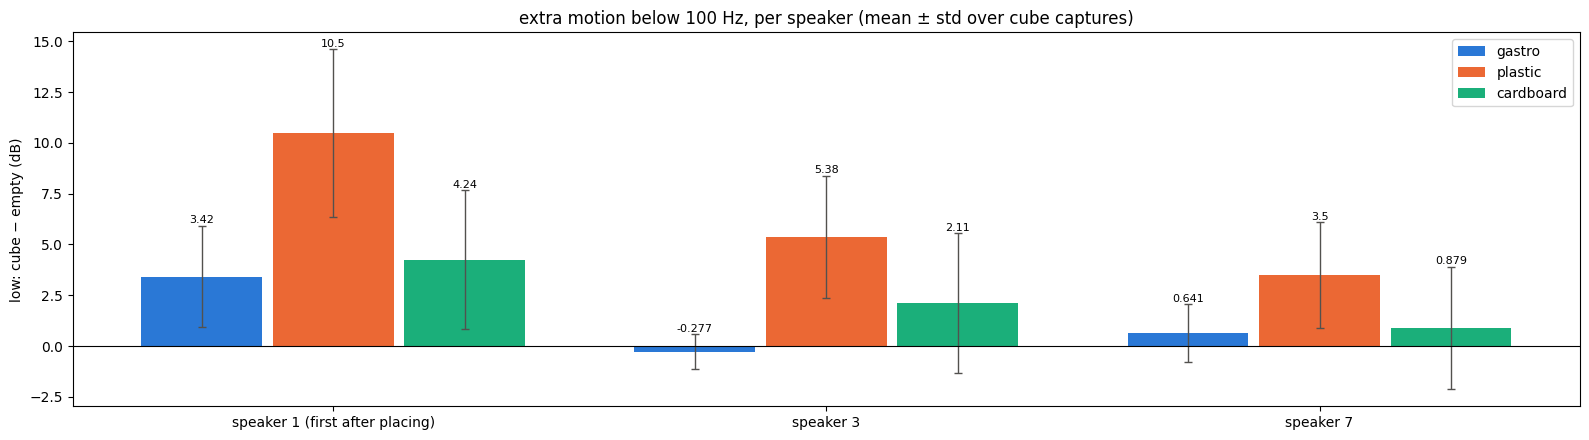

In [16]:
fig, ax = plt.subplots(figsize=(16, 4.5))
bars(ax, [f"speaker {s}" + (" (first after placing)" if s == 1 else "") for s in SPK],
     {b: [excess(lo, b, s).mean() for s in SPK] for b in BOXES}, {b: [excess(lo, b, s).std() for s in SPK] for b in BOXES})
ax.axhline(0, c="k", lw=.8)
ax.set(ylabel="low: cube − empty (dB)", title="extra motion below 100 Hz, per speaker (mean ± std over cube captures)")
plt.tight_layout()
show(*[f"low, speaker {s} (dB)" for s in SPK])

**Reading:**
- **Yes: in every box speaker 1 has the most extra low-frequency motion.** Gastro +3.4 dB vs ≤ 0.6 for the others, cardboard +4.2 vs 2.1 and 0.9, plastic +10.5 vs 5.4 and 3.5.
- It settles within seconds. In gastro and cardboard it has mostly died out 1.5 s later (speaker 3). In plastic it is still +3.5 dB at speaker 7.
- **Cardboard is not the box that shakes most:** plastic gets ~6 dB more extra motion than cardboard and takes longest to settle, yet predicts the cube best.
- The spread is wide (±3 dB): some placements barely move the box, others move it a lot.

## 7.2 Does the Placement Motion Get Through the 100 Hz High-Pass?

`excess(f)` from 5 to 1000 Hz, mean ± std over cube captures; the gray region is what the band-pass removes (5th-order Butterworth run forward and backward: −12 dB at 90 Hz, −33 dB at 70 Hz, −63 dB at 50 Hz). Above 100 Hz all speakers carry the cube's real effect on the spectrum. Placement motion would show as speaker 1 sitting **above** speakers 3 and 7 there.

,gastro,plastic,cardboard
"in-band, speaker 1 (dB)",0.3 ± 0.3,-0.4 ± 0.4,-0.6 ± 0.2
"in-band, speaker 3 (dB)",0.1 ± 0.5,-0.1 ± 0.3,-0.3 ± 0.1
"in-band, speaker 7 (dB)",0.3 ± 0.3,0.6 ± 0.6,0.1 ± 0.2
"move / noise, speaker 1",0.31,1.25,0.28
"move / noise, speaker 3",0.30,0.90,0.22
"move / noise, speaker 7",0.45,0.93,0.51


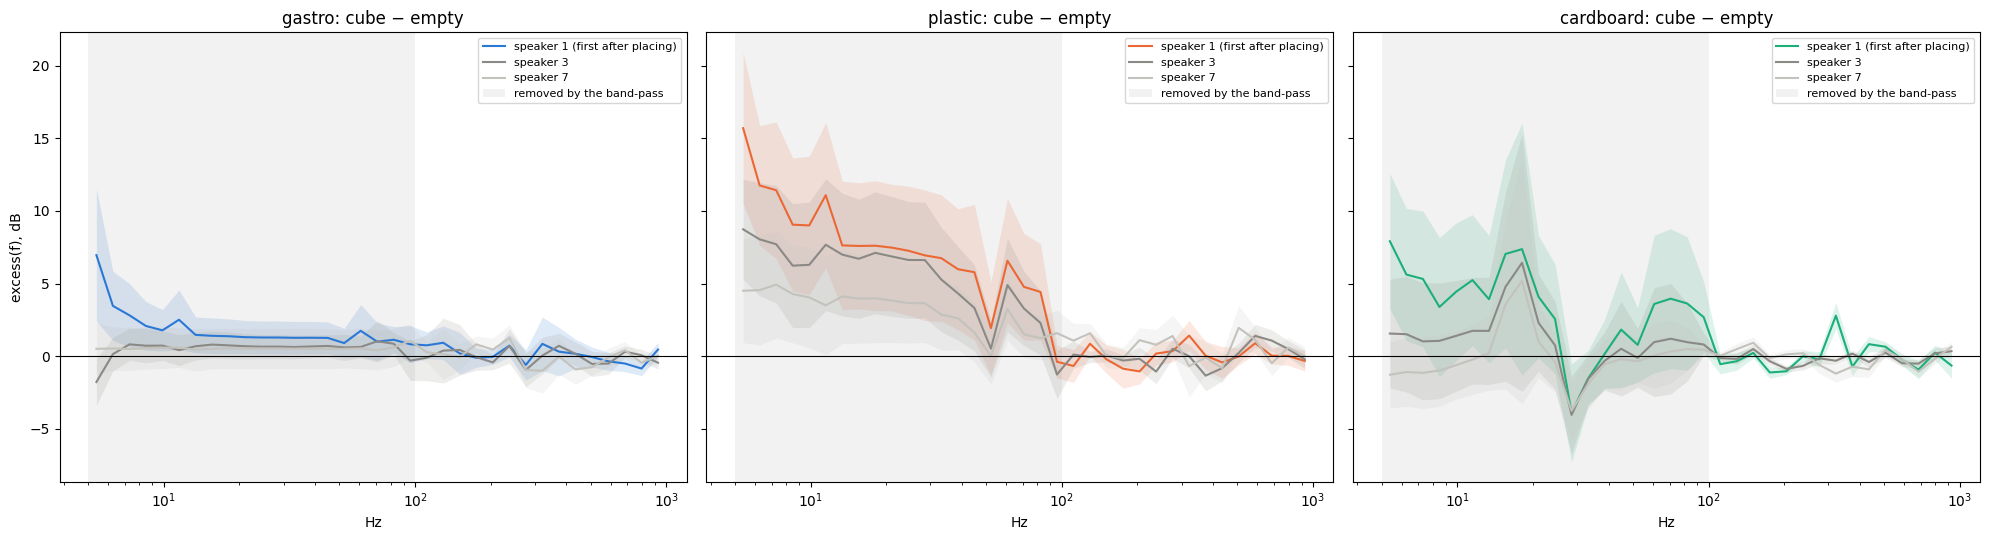

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
for ax, box in zip(axs, BOXES):
    for spk, c in SPK.items(): band(ax, fl, excess(R, box, spk), c or COLORS[box], f"speaker {spk}" + (" (first after placing)" if spk == 1 else ""))
    ax.axvspan(5, 100, color="gray", alpha=.1, lw=0, label="removed by the band-pass")
    ax.axhline(0, c="k", lw=.8)
    ax.set(xscale="log", xlabel="Hz", title=f"{box}: cube − empty")
    ax.legend(fontsize=8)
axs[0].set_ylabel("excess(f), dB")
plt.tight_layout()
show(*[f"in-band, speaker {s} (dB)" for s in SPK], *[f"move / noise, speaker {s}" for s in SPK])

**Reading:**
- **Below 100 Hz** (gray) speaker 1 sits above speakers 3 and 7 in every box: that is the placement motion from 7.1.
- **At 100 Hz the gap closes.** Above 100 Hz speaker 1 lies on top of speakers 3 and 7, inside their ±1 std bands, in all three boxes. Placing the cube adds nothing the model sees.
- In total 100-1000 Hz energy speaker 1 is not higher than the others: −0.6 dB in cardboard and −0.4 in plastic (speaker 7: +0.1 and +0.6), +0.3 in gastro (speaker 7: +0.3).
- Speaker 1 also does not have the worst position signal (`move/noise`, section 4): in cardboard it is 0.28, between speaker 3 (0.22) and speaker 7 (0.51).
- Cardboard's peak near 18 Hz and dip near 28 Hz show up for every speaker. They are the cube changing the box's low modes, not placement, and they are removed too.

**H6 verdict: false.** Placing the cube does shake the box, but the motion is concentrated in speaker 1 and below 100 Hz, where the band-pass removes it (−63 dB at 50 Hz). None of it survives in 100-1000 Hz. And cardboard is not the box that shakes most: plastic is, and it predicts the cube best.

# 8 Conclusion

Every result in the notebook, grouped by hypothesis (mean ± std over the unit of each section).

In [18]:
RESULTS = {
    "H1 noise": ["noise = D_spec of pairs (dB)", "N, mean over f (dB)"],
    "H2 level": ["level L, mean over f (dB)", "SNR = L − N, mean over f (dB)"],
    "H3 position signal": ["cue (dB)", "move (dB)", "move / noise"],
    "H4 damping": ["time to noise 100-1000 Hz (s)", "T60 100-200 Hz (s)", "T60 200-400 Hz (s)", "T60 400-800 Hz (s)", "η (log-mean per capture)", "energy lost per cycle 2πη (%)", "Q = 1/η", "measurable modes per capture"],
    "H5 spatial patterns": ["eff_rank all", "eff_rank cube", "eff_rank empty", "n90"],
    "H6 placement": ["low, speaker 1 (dB)", "low, speaker 3 (dB)", "low, speaker 7 (dB)", "in-band, speaker 1 (dB)", "in-band, speaker 3 (dB)", "in-band, speaker 7 (dB)"],
}
pd.concat({h: show(*k) for h, k in RESULTS.items()}, names=["hypothesis", "metric"])

gastro  \
hypothesis          metric                                                      
H1 noise            noise = D_spec of pairs (dB)                  1.45 ± 0.37   
                    N, mean over f (dB)                           -28.6 ± 1.9   
H2 level            level L, mean over f (dB)                      -8.3 ± 1.7   
                    SNR = L − N, mean over f (dB)                  20.3 ± 1.7   
H3 position signal  cue (dB)                                      2.76 ± 0.06   
                    move (dB)                                     0.50 ± 0.02   
                    move / noise                                  0.35 ± 0.07   
H4 damping          time to noise 100-1000 Hz (s)  0.56 ± 0.09 (33% reach it)   
                    T60 100-200 Hz (s)                            3.55 ± 0.36   
                    T60 200-400 Hz (s)                            1.85 ± 0.14   
                    T60 400-800 Hz (s)                            1.40 ± 0.29   
                    η (log-mean per capture)                    0.006 ± 0.001   
                    energy lost per cycle 2πη (%)                       4 ± 0   
                    Q = 1/η                                          167 ± 23   
                    measurable modes per capture                       42 ± 4   
H5 spatial patterns eff_rank all                                    9.2 ± 0.2   
                    eff_rank cube                                   9.1 ± 0.2   
                    eff_rank empty                                  9.0 ± 0.2   
                    n90                                            13.0 ± 0.8   
H6 placement        low, speaker 1 (dB)                             3.4 ± 2.5   
                    low, speaker 3 (dB)                            -0.3 ± 0.8   
                    low, speaker 7 (dB)                             0.6 ± 1.4   
                    in-band, speaker 1 (dB)                         0.3 ± 0.3   
                    in-band, speaker 3 (dB)                         0.1 ± 0.5   
                    in-band, speaker 7 (dB)                         0.3 ± 0.3   

                                                         plastic  \
hypothesis          metric                                         
H1 noise            noise = D_spec of pairs (dB)     1.29 ± 0.34   
                    N, mean over f (dB)              -29.9 ± 2.3   
H2 level            level L, mean over f (dB)         -7.7 ± 2.2   
                    SNR = L − N, mean over f (dB)     22.2 ± 2.2   
H3 position signal  cue (dB)                         4.37 ± 0.15   
                    move (dB)                        1.31 ± 0.14   
                    move / noise                     1.03 ± 0.15   
H4 damping          time to noise 100-1000 Hz (s)    0.37 ± 0.08   
                    T60 100-200 Hz (s)               0.34 ± 0.06   
                    T60 200-400 Hz (s)               0.23 ± 0.03   
                    T60 400-800 Hz (s)               0.17 ± 0.04   
                    η (log-mean per capture)       0.039 ± 0.007   
                    energy lost per cycle 2πη (%)         24 ± 4   
                    Q = 1/η                               27 ± 5   
                    measurable modes per capture           4 ± 1   
H5 spatial patterns eff_rank all                       8.4 ± 0.4   
                    eff_rank cube                      7.8 ± 0.4   
                    eff_rank empty                     7.8 ± 0.4   
                    n90                               13.7 ± 3.1   
H6 placement        low, speaker 1 (dB)               10.5 ± 4.1   
                    low, speaker 3 (dB)                5.4 ± 3.0   
                    low, speaker 7 (dB)                3.5 ± 2.6   
                    in-band, speaker 1 (dB)           -0.4 ± 0.4   
                    in-band, speaker 3 (dB)           -0.1 ± 0.3   
                    in-band, speaker 7 (dB)            0.6 ± 0.6   

                                              

## Verdicts

| | Hypothesis | Key number: gastro / plastic / cardboard | Verdict |
|---|---|---|---|
| H1 | the capture is noisier | noise 1.45 / 1.29 / 1.64 dB | **false**: no noisier than gastro |
| H2 | the box absorbs the vibration | level −8.3 / −7.7 / −4.5 dB | **false**: cardboard is the loudest |
| H3 | moving the cube barely changes the spectrum | move/noise 0.35 / 1.03 / 0.34 | **true, but = gastro**: not the gap |
| H4 | the box is damped | η 0.006 / 0.039 / 0.055 | **true, but shared with plastic** |
| H5 | few distinct spatial patterns | eff_rank 9.2 / 8.4 / 5.4 | **true, cardboard-only** |
| H6 | placing the cube shakes the box | speaker 1 below 100 Hz +3.4 / +10.5 / +4.2 dB; 100-1000 Hz +0.3 / −0.4 / −0.6 dB | **false**: below 100 Hz, filtered out; plastic shakes most |
| | *cube IoU (nb98)* | *0.34 / 0.64 / 0.11* | |

## Answer

**Why is the cube harder to predict in cardboard?** Cardboard is the only box that is weak on *both* things a model can use to localize the cube: a position signal above the noise (H3) and many distinct spatial patterns (H5).

| | position signal (`move/noise`) | distinct spatial patterns (`eff_rank`) | damping (η) | cube IoU |
|---|---|---|---|---|
| gastro | weak (0.35) | many (9.2) | low (0.006) | 0.34 |
| plastic | **strong (1.03)** | many (8.4) | high (0.039) | **0.64** |
| cardboard | weak (0.34) | **few (5.4)** | high (0.055) | **0.11** |

1. **Not noise, absorption or handling (H1, H2, H6).** Cardboard is the loudest box, and its SNR is between gastro's and plastic's. Placing the cube shakes the box only below 100 Hz, which the band-pass removes.
2. **A weak position signal is not enough (H3).** Gastro is just as weak and still predicts the cube 3× better.
3. **Damping is not enough either (H4).** Plastic is about as damped and predicts the cube best.
4. **Few spatial patterns is what only cardboard has (H5).** Gastro makes up for its weak position signal with many sharp, distinct modes. Plastic is damped, but its spatial shape keeps changing with frequency and the cube moves its spectrum strongly. Cardboard is damped *and* its broad modes collapse onto ~5 spatial patterns, so the cube's position has few ways to show up.

## Open Questions (from earlier analyses, not shown here)

- **The runs are not matched.** `s7-card-base-3k` uses src7, speakers 1/3/5/7 and more objects; `gastro-3k` and `plastic-3k` use speakers 1/3/7. Part of the IoU gap may be the training setup.
- **Coarse position is decodable.** On a 3×3 grid, nearest-centroid decoding from the spectrum is about as good in cardboard (0.52) as in gastro (0.42-0.56). The deficit may be in fine localization, or in training.
- **Recording order.** The cube was recorded first in the cardboard (and gastro) sessions, when repeat noise was highest, and the nearest spectrum is usually the capture taken seconds earlier.
- **The Hann window.** `post_process.clean` windows the whole 1.3 s capture. With a log sweep, that strongly attenuates the start and end of the sweep (~100 Hz and ~1000 Hz) in every box.

## What to Try

1. **Train a cardboard run with gastro-3k's exact config** (speakers 1/3/7, same objects, same code) to measure how much of the gap is the box.
2. **Re-record one cardboard cube grid** later in a session, with a longer capture (2-2.5 s, so ringing isn't cut) and empty references every ~10 min.
3. If cardboard is still poor, **it is a weak sensor for the cube**: use a stiffer, less damped box, or stiffen the cardboard wall the lasers see.